# Indian Railway Train Delay Prediction Using Linear Regression

**Student:** Khushbu Sharma |
**Roll No:** GF202455346 |
**Project:** T1 (P2)
**Subject:** Machine Learning |
**University:** Shoolini University
**Dataset:** Indian Railways - Delay Dataset (Kaggle)
**Algorithm:** Linear Regression (Supervised Learning, Regression)

## Notebook Contents
1. Dataset Understanding
2. Data Cleaning
3. Exploratory Data Analysis
4. Outlier Analysis
5. Correlation Analysis
6. Pre-modelling Checks and Split Design
7. Model Table and Baseline Linear Regression
8. Leakage-Safe History Features and Multicollinearity Check
9. Residual Analysis
10. Final Model Choice and Final Evaluation
11. Report and Presentation Material
12. Final Conclusions

In [4]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

DATA_FOLDER = r"D:\Indian_Railway_Delay_Project\data"

DELAY_FILE    = os.path.join(DATA_FOLDER, "combined_delay.csv")
SCHEDULE_FILE = os.path.join(DATA_FOLDER, "combined_schedule.csv")
STATION_FILE  = os.path.join(DATA_FOLDER, "station_full_names.csv")
TRAIN_FILE    = os.path.join(DATA_FOLDER, "train_details.csv")

print("Setup complete")

Setup complete


# Phase 1: Dataset Understanding
**Goal:** Understand the structure, columns, data types, size and limitations of all four dataset files before any cleaning or modelling.

In [12]:
for f in os.listdir(DATA_FOLDER):
    size_mb = os.path.getsize(os.path.join(DATA_FOLDER, f)) / (1024 * 1024)
    print(f"{f:30s} {size_mb:10.2f} MB")

combined_delay.csv                 969.71 MB
combined_schedule.csv                5.24 MB
station_full_names.csv               0.44 MB
train_details.csv                    0.28 MB


In [14]:
train_details = pd.read_csv(TRAIN_FILE)
stations      = pd.read_csv(STATION_FILE)
schedule      = pd.read_csv(SCHEDULE_FILE)

print("train_details :", train_details.shape)
print("stations      :", stations.shape)
print("schedule      :", schedule.shape)

train_details : (8992, 3)
stations      : (8963, 4)
schedule      : (172112, 8)


In [16]:
print("Columns:", train_details.columns.tolist())
display(train_details.head())
display(train_details.tail())
train_details.info()
print("\nMissing values:")
display(train_details.isnull().sum())
print("Unique train numbers:", train_details["train_no"].nunique())
print("\nTrain types:")
display(train_details["type_code"].value_counts())

Columns: ['train_no', 'train_name', 'type_code']


,train_no,train_name,type_code
0,1211,BD NK SPL,PASS-TRAINS
1,1212,NK BD SPL,PASS-TRAINS
2,1461,SUR DD DMU SPL,PASS-TRAINS
3,1462,DD SUR DMU SPL,PASS-TRAINS
4,3020,AZ KNJ PASS SPL,PASS-TRAINS


,train_no,train_name,type_code
8987,69208,VTDI GNC MEMU,PRM-TRAINS
8988,82501,IRCTC TEJAS EXP,PRM-TRAINS
8989,82502,IRCTC TEJAS EXP,PRM-TRAINS
8990,82901,MMCT ADI TEJAS,PRM-TRAINS
8991,82902,IRCTC TEJAS EXP,PRM-TRAINS


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8992 entries, 0 to 8991
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   train_no    8992 non-null   int64 
 1   train_name  8992 non-null   object
 2   type_code   8992 non-null   object
dtypes: int64(1), object(2)
memory usage: 210.9+ KB

Missing values:


train_no      0
train_name    0
type_code     0
dtype: int64

Unique train numbers: 8720

Train types:


type_code
PASS-TRAINS    4538
EXP-TRAINS     2255
SF-TRAINS      1382
PRM-TRAINS      448
T18-TRAINS      198
SHT-TRAINS       64
GRB-TRAINS       54
RAJ-TRAINS       53
Name: count, dtype: int64

In [18]:
print("Columns:", stations.columns.tolist())
display(stations.head())
display(stations.tail())
stations.info()
print("\nMissing values:")
display(stations.isnull().sum())
print("Unique station codes:", stations["station_name"].nunique())
print("\nRailway zones:")
display(stations["station_zone"].value_counts())

Columns: ['station_name', 'station_full_name', 'station_zone', 'station_address']


,station_name,station_full_name,station_zone,station_address
0,AA,ATARIA,NER,"Sitapur Rd, Heerpur, Uttar Pradesh 261.."
1,AABH,AMBIKA BHAWANI HALT,ECR,"Chapra-Patna Highway, Rampur Ami, Biha.."
2,AADR,AMBANDAURA,NR,"Una, Himachal Pradesh, India"
3,AAG,ANGAR,CR,"Solapur, Maharashtra, India"
4,AAGH,ANTAGARH,SECR,"Antagarh, PIN - 494665, Dist. - Kanker.."


,station_name,station_full_name,station_zone,station_address
8958,ZPI,ZAMPINI,SCR,"Zampini Station, Andhra Pradesh, India"
8959,ZPL,ZANGALAPALLE,SCR,"Mallepalle, Andhra Pradesh, India"
8960,ZPR,ZORAWARPURA,NWR,"55 F, Rajasthan 335024, India"
8961,ZRDE,JIRADEI,NER,"Siwan, Bihar, India"
8962,ZW,ZAWAR,NWR,"Udaipur, Rajasthan, India"


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8963 entries, 0 to 8962
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   station_name       8963 non-null   object
 1   station_full_name  8963 non-null   object
 2   station_zone       8963 non-null   object
 3   station_address    8869 non-null   object
dtypes: object(4)
memory usage: 280.2+ KB

Missing values:


station_name          0
station_full_name     0
station_zone          0
station_address      94
dtype: int64

Unique station codes: 8963

Railway zones:


station_zone
NR      1047
ECR      781
SCR      758
SR       735
WR       705
ER       587
NWR      586
NFR      558
NER      501
CR       468
NCR      425
SWR      400
SER      373
ECOR     340
SECR     311
WCR      309
KR        72
BR         5
SCOR       2
Name: count, dtype: int64

In [20]:
print("Columns:", schedule.columns.tolist())
display(schedule.head())
display(schedule.tail())
schedule.info()
print("\nMissing values:")
display(schedule.isnull().sum())
print("Unique trains in schedule:", schedule["train_no"].nunique())
print("Unique stations in schedule:", schedule["station_name"].nunique())
display(schedule.describe())

Columns: ['station_no', 'station_name', 'distance_from_origin', 'arrival_day', 'arrival_time', 'departure_day', 'departure_time', 'train_no']


,station_no,station_name,distance_from_origin,arrival_day,arrival_time,departure_day,departure_time,train_no
0,1,MJ,0,1,NaN,1,09:45,961
1,2,FLD,26,1,11:00,1,11:15,961
2,3,KBK,47,1,12:45,1,NaN,961
3,1,KBK,0,1,NaN,1,14:30,962
4,2,FLD,22,1,16:00,1,16:15,962


,station_no,station_name,distance_from_origin,arrival_day,arrival_time,departure_day,departure_time,train_no
172107,31,BKG,272,2,07:36,2,07:37,83131
172108,32,PNC,279,2,07:43,2,07:44,83131
172109,33,GZH,281,2,07:51,2,07:52,83131
172110,34,RJPB,286,2,08:01,2,08:03,83131
172111,35,PNBE,288,2,08:25,2,NaN,83131


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 172112 entries, 0 to 172111
Data columns (total 8 columns):
 #   Column                Non-Null Count   Dtype 
---  ------                --------------   ----- 
 0   station_no            172112 non-null  int64 
 1   station_name          172112 non-null  object
 2   distance_from_origin  172112 non-null  int64 
 3   arrival_day           172112 non-null  int64 
 4   arrival_time          163439 non-null  object
 5   departure_day         172112 non-null  int64 
 6   departure_time        163439 non-null  object
 7   train_no              172112 non-null  int64 
dtypes: int64(5), object(3)
memory usage: 10.5+ MB

Missing values:


station_no                 0
station_name               0
distance_from_origin       0
arrival_day                0
arrival_time            8673
departure_day              0
departure_time          8673
train_no                   0
dtype: int64

Unique trains in schedule: 8673
Unique stations in schedule: 8629


,station_no,distance_from_origin,arrival_day,departure_day,train_no
count,172112.000000,172112.000000,172112.000000,172112.000000,172112.000000
mean,14.785727,381.132083,1.318432,1.318914,36010.738043
std,12.964000,542.790912,0.546866,0.547186,24264.522921
min,1.000000,0.000000,1.000000,1.000000,961.000000
25%,6.000000,49.000000,1.000000,1.000000,14734.000000
50%,11.000000,145.000000,1.000000,1.000000,22130.000000
75%,20.000000,472.000000,2.000000,2.000000,58505.000000
max,119.000000,4188.000000,4.000000,4.000000,83131.000000


In [22]:
peek = pd.read_csv(DELAY_FILE, nrows=10)

print("Columns:", peek.columns.tolist())
display(peek)
peek.info()

Columns: ['date', 'station_no', 'station_name', 'delay', 'train_no']


,date,station_no,station_name,delay,train_no
0,2025-02-08,1,MJ,NaN,961
1,2025-02-10,1,MJ,NaN,961
2,2025-02-12,1,MJ,0.0,961
3,2025-02-13,1,MJ,0.0,961
4,2025-02-22,1,MJ,0.0,961
5,2025-02-23,1,MJ,0.0,961
6,2025-02-24,1,MJ,0.0,961
7,2025-03-08,1,MJ,0.0,961
8,2025-03-09,1,MJ,0.0,961
9,2025-03-10,1,MJ,0.0,961


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   date          10 non-null     object 
 1   station_no    10 non-null     int64  
 2   station_name  10 non-null     object 
 3   delay         8 non-null      float64
 4   train_no      10 non-null     int64  
dtypes: float64(1), int64(2), object(2)
memory usage: 532.0+ bytes


In [24]:
total_rows = 0
min_date = None
max_date = None

for chunk in pd.read_csv(DELAY_FILE, usecols=["date"], chunksize=2_000_000):
    total_rows += len(chunk)
    cmin, cmax = chunk["date"].min(), chunk["date"].max()
    if min_date is None or cmin < min_date:
        min_date = cmin
    if max_date is None or cmax > max_date:
        max_date = cmax

print("Total rows in combined_delay:", total_rows)
print("Earliest date:", min_date)
print("Latest date  :", max_date)

Total rows in combined_delay: 38428703
Earliest date: 2025-02-08
Latest date  : 2026-02-07


In [26]:
summary = pd.DataFrame({
    "File": ["combined_delay", "combined_schedule", "station_full_names", "train_details"],
    "Rows": [total_rows, schedule.shape[0], stations.shape[0], train_details.shape[0]],
    "Columns": [5, schedule.shape[1], stations.shape[1], train_details.shape[1]]
})
display(summary)

,File,Rows,Columns
0,combined_delay,38428703,5
1,combined_schedule,172112,8
2,station_full_names,8963,4
3,train_details,8992,3


In [8]:
import os
import pandas as pd
import numpy as np

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

DATA_FOLDER = r"D:\Indian_Railway_Delay_Project\data"

TRAIN_FILE    = os.path.join(DATA_FOLDER, "train_details.csv")
STATION_FILE  = os.path.join(DATA_FOLDER, "station_full_names.csv")
SCHEDULE_FILE = os.path.join(DATA_FOLDER, "combined_schedule.csv")
DELAY_FILE    = os.path.join(DATA_FOLDER, "combined_delay.csv")

# Load the three small files again
train_details = pd.read_csv(TRAIN_FILE)
stations      = pd.read_csv(STATION_FILE)
schedule      = pd.read_csv(SCHEDULE_FILE)

# Duplicate train check
dup_trains = train_details[train_details["train_no"].duplicated(keep=False)] \
                .sort_values("train_no")

print("Rows involved in duplication:", len(dup_trains))
display(dup_trains.head(20))

print("Exact duplicate rows:", train_details.duplicated().sum())
print("Duplicate train_no  :", train_details["train_no"].duplicated().sum())

Rows involved in duplication: 544


,train_no,train_name,type_code
4549,1042,SNSI DR SPECIAL,EXP-TRAINS
8544,1042,SNSI DR SPECIAL,PRM-TRAINS
8547,1265,MML ABKP SPL,PRM-TRAINS
4556,1265,MML ABKP SPL,EXP-TRAINS
8548,1266,ABKP JBP SPL,PRM-TRAINS
4557,1266,ABKP JBP SPL,EXP-TRAINS
8549,1271,ET BPL SPECIAL,PRM-TRAINS
4558,1271,ET BPL SPECIAL,EXP-TRAINS
8550,1272,BPL ET SPECIAL,PRM-TRAINS
4559,1272,BPL ET SPECIAL,EXP-TRAINS


Exact duplicate rows: 0
Duplicate train_no  : 272


## PHASE 2: DATA CLEANING
A. What are we doing?

Checking and fixing data quality: duplicate train types, missing delays, wrong data types, negative and extreme delays, and consistency between files.

B. Why are we doing it?

Bad or duplicated data misleads the model and inflates results.

C. Concepts
Duplicate key: the same identifier appearing more than once.
NaN delay: it may mean "not recorded" or "cancelled". We will not blindly fill it with 0.
Memory-efficient dtypes: int16, int32, float32, category shrink 38M rows to fit in 16 GB.
Negative delay: possibly an early arrival.

In [12]:
dup_trains = train_details[train_details["train_no"].duplicated(keep=False)]

# Which type combinations occur across the 272 repeated trains?
combos = (dup_trains.groupby("train_no")["type_code"]
          .apply(lambda s: " + ".join(sorted(s))))
display(combos.value_counts())

# Do the names agree within each pair?
print("Trains whose name differs between copies:",
      (dup_trains.groupby("train_no")["train_name"].nunique() > 1).sum())

type_code
PRM-TRAINS + T18-TRAINS     194
EXP-TRAINS + PRM-TRAINS      40
PASS-TRAINS + PRM-TRAINS     17
PRM-TRAINS + SHT-TRAINS      14
PASS-TRAINS + T18-TRAINS      4
PRM-TRAINS + RAJ-TRAINS       3
Name: count, dtype: int64

Trains whose name differs between copies: 0


In [16]:
dtypes = {"station_no": "int16", "station_name": "category",
          "train_no": "int32", "delay": "float32"}

delay_df = pd.read_csv(DELAY_FILE, dtype=dtypes, parse_dates=["date"])
print("Loaded:", delay_df.shape)
print("Memory (GB):", round(delay_df.memory_usage(deep=True).sum() / 1024**3, 2))
delay_df.info()

Loaded: (38428703, 5)
Memory (GB): 0.72
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38428703 entries, 0 to 38428702
Data columns (total 5 columns):
 #   Column        Dtype         
---  ------        -----         
 0   date          datetime64[ns]
 1   station_no    int16         
 2   station_name  category      
 3   delay         float32       
 4   train_no      int32         
dtypes: category(1), datetime64[ns](1), float32(1), int16(1), int32(1)
memory usage: 733.3 MB


In [17]:
miss = delay_df.isnull().sum()
display(pd.DataFrame({"missing": miss,
                      "percent": (miss / len(delay_df) * 100).round(2)}))
display(delay_df["delay"].describe())

,missing,percent
date,0,0.00
station_no,0,0.00
station_name,0,0.00
delay,1874271,4.88
train_no,0,0.00


count    3.655443e+07
mean     3.693554e+01
std      2.730817e+02
min     -1.200000e+02
25%      4.000000e+00
50%      1.600000e+01
75%      4.100000e+01
max      5.255920e+05
Name: delay, dtype: float64

In [18]:
d = delay_df["delay"]
print("Negative:", (d < 0).sum(), "| Zero:", (d == 0).sum(), "| Positive:", (d > 0).sum())
print("Most negative:", d.nsmallest(10).tolist())
print("Largest      :", d.nlargest(10).tolist())
for limit in [60, 180, 360, 720, 1440]:
    print(f"> {limit} min:", (d > limit).sum())

Negative: 773174 | Zero: 4898984 | Positive: 30882274
Most negative: [-120.0, -120.0, -120.0, -120.0, -119.0, -119.0, -119.0, -119.0, -119.0, -118.0]
Largest      : [525592.0, 525585.0, 525582.0, 525581.0, 525569.0, 525546.0, 525545.0, 525545.0, 525525.0, 7018.0]
> 60 min: 5938963
> 180 min: 1136874
> 360 min: 271761
> 720 min: 55888
> 1440 min: 15073


In [22]:
key = ["train_no", "date", "station_no"]
print("Duplicates on key:", delay_df.duplicated(subset=key).sum())
print("Fully identical rows:", delay_df.duplicated().sum())

Duplicates on key: 0
Fully identical rows: 0


In [26]:
# Lower rank number = more specific type, which we prefer to keep
priority = {"T18-TRAINS": 1, "RAJ-TRAINS": 2, "SHT-TRAINS": 3, "GRB-TRAINS": 4,
            "EXP-TRAINS": 5, "SF-TRAINS": 6, "PASS-TRAINS": 7, "PRM-TRAINS": 8}

td = train_details.copy()
td["rank"] = td["type_code"].map(priority)

# Remember which trains carried a PRM label before we drop it
has_prm = td.groupby("train_no")["type_code"].apply(lambda s: (s == "PRM-TRAINS").any())

train_clean = (td.sort_values(["train_no", "rank"])
                 .drop_duplicates(subset="train_no", keep="first")
                 .drop(columns="rank"))
train_clean["has_prm_label"] = train_clean["train_no"].map(has_prm)

print("Rows:", len(train_clean), "| Unique trains:", train_clean["train_no"].nunique())
display(train_clean["type_code"].value_counts())
print("Trains with PRM label:", train_clean["has_prm_label"].sum())

Rows: 8720 | Unique trains: 8720


type_code
PASS-TRAINS    4534
EXP-TRAINS     2255
SF-TRAINS      1382
T18-TRAINS      198
PRM-TRAINS      180
SHT-TRAINS       64
GRB-TRAINS       54
RAJ-TRAINS       53
Name: count, dtype: int64

Trains with PRM label: 448


In [23]:
delay_trains = set(delay_df["train_no"].unique())
print("Trains in delay file     :", len(delay_trains))
print("Not in train_details     :", len(delay_trains - set(train_clean["train_no"])))
print("Not in schedule          :", len(delay_trains - set(schedule["train_no"])))

delay_stations = set(delay_df["station_name"].unique())
print("Stations not in station file:", len(delay_stations - set(stations["station_name"])))

Trains in delay file     : 7033
Not in train_details     : 0
Not in schedule          : 33
Stations not in station file: 63


In [28]:
miss = delay_df["delay"].isna()

print("Missing % at origin stop (station_no == 1):",
      round(miss[delay_df["station_no"] == 1].mean() * 100, 2))
print("Missing % at other stops:",
      round(miss[delay_df["station_no"] != 1].mean() * 100, 2))

print("\nMissing % by month:")
display((miss.groupby(delay_df["date"].dt.to_period("M")).mean() * 100).round(2))

tmp = pd.DataFrame({"train_no": delay_df["train_no"],
                    "date": delay_df["date"],
                    "is_missing": miss})
j = tmp.groupby(["train_no", "date"]).agg(stops=("is_missing", "size"),
                                          missing=("is_missing", "sum"))
print("\nTotal journeys:", len(j))
print("Journeys with ALL stops missing :", (j["missing"] == j["stops"]).sum())
print("Journeys with SOME stops missing:", ((j["missing"] > 0) & (j["missing"] < j["stops"])).sum())
del tmp

Missing % at origin stop (station_no == 1): 4.17
Missing % at other stops: 4.91

Missing % by month:


date
2025-02    11.19
2025-03     6.79
2025-04     4.35
2025-05     4.19
2025-06     4.01
2025-07     3.79
2025-08     3.32
2025-09     2.68
2025-10     3.34
2025-11     3.88
2025-12     6.34
2026-01     6.37
2026-02     5.70
Freq: M, Name: delay, dtype: float64


Total journeys: 1895758
Journeys with ALL stops missing : 34317
Journeys with SOME stops missing: 493274


In [29]:
d = delay_df["delay"]
extreme = delay_df[d > 7000].sort_values("delay", ascending=False)
display(extreme)
print("Largest values in days:", (extreme["delay"] / 1440).round(2).tolist())

for lo, hi in [(1440, 2880), (2880, 4320), (4320, 7000)]:
    print(f"{lo} to {hi} min:", ((d > lo) & (d <= hi)).sum())

,date,station_no,station_name,delay,train_no
35375076,2025-12-31,4,PRTN,525592.0,69206
30895989,2025-12-31,30,SRE,525585.0,64565
9014830,2025-12-31,23,SGNR,525582.0,14816
29678373,2025-12-31,40,BKSC,525581.0,63519
13973804,2025-12-31,21,MRJ,525569.0,17334
15195547,2025-12-31,79,PURI,525546.0,18125
28383033,2025-12-31,11,ARA,525545.0,63223
32792488,2025-12-31,38,GDR,525545.0,67225
33126098,2025-12-31,22,RJY,525525.0,67286
934655,2025-11-03,7,KYN,7018.0,11008


Largest values in days: [364.989990234375, 364.989990234375, 364.989990234375, 364.989990234375, 364.9800109863281, 364.9599914550781, 364.9599914550781, 364.9599914550781, 364.95001220703125, 4.869999885559082, 4.869999885559082, 4.869999885559082, 4.869999885559082]
1440 to 2880 min: 9943
2880 to 4320 min: 3496
4320 to 7000 min: 1621


In [32]:
no_sched_trains = set(delay_df["train_no"].unique()) - set(schedule["train_no"])
no_station_codes = set(delay_df["station_name"].unique()) - set(stations["station_name"])

print("Delay rows of trains missing from schedule:", delay_df["train_no"].isin(no_sched_trains).sum())
print("Delay rows at stations missing from station file:", delay_df["station_name"].isin(no_station_codes).sum())
print("Example station codes:", sorted(no_station_codes)[:15])

Delay rows of trains missing from schedule: 77142
Delay rows at stations missing from station file: 106475
Example station codes: ['AE', 'AEP', 'AJLE', 'AWB', 'BADR', 'BARS', 'BEED', 'BIGN', 'BKCA', 'BLRA', 'BMAP', 'BNDE', 'BPHI', 'BRIP', 'BSBS']


In [34]:
# 1. Remove rows with no delay value (no target to learn from)
clean = delay_df[delay_df["delay"].notna()]
print("After removing missing delay:", len(clean))   # expect 36,554,432

# 2. Remove the 9 impossible ~365-day values (anything above 400,000 minutes)
before = len(clean)
clean = clean[clean["delay"] < 400_000].copy()
print("Rows removed as impossible  :", before - len(clean))   # expect 9
print("Final rows                  :", len(clean))            # expect 36,554,423

# 3. Add train type and PRM flag using .map (saves memory compared with merge)
type_map = train_clean.set_index("train_no")["type_code"]
prm_map  = train_clean.set_index("train_no")["has_prm_label"]
clean["type_code"]     = clean["train_no"].map(type_map).astype("category")
clean["has_prm_label"] = clean["train_no"].map(prm_map).astype("bool")

# 4. Verify
print("\nMissing values after cleaning:")
display(clean.isnull().sum())
print("Delay statistics after cleaning:")
display(clean["delay"].describe())

# 5. Save so we don't have to reload the 969 MB file next time
clean.to_pickle(r"D:\Indian_Railway_Delay_Project\delay_clean.pkl")
print("Saved.")

After removing missing delay: 36554432
Rows removed as impossible  : 9
Final rows                  : 36554423

Missing values after cleaning:


date             0
station_no       0
station_name     0
delay            0
train_no         0
type_code        0
has_prm_label    0
dtype: int64

Delay statistics after cleaning:


count    3.655442e+07
mean     3.680612e+01
std      8.458070e+01
min     -1.200000e+02
25%      4.000000e+00
50%      1.600000e+01
75%      4.100000e+01
max      7.018000e+03
Name: delay, dtype: float64

Saved.


In [36]:
clean = pd.read_pickle(r"D:\Indian_Railway_Delay_Project\delay_clean.pkl")

### PHASE 3: EXPLORATORY DATA ANALYSIS (EDA)
A. What are we doing?

Summarizing and visualizing the cleaned delay data to find patterns: overall distribution, train types, stations, zones, and time (month, weekday).

B. Why are we doing it?

EDA shows what the data looks like before modelling. It guides outlier handling, feature choices and the final conclusions.

C. Concepts involved
Mean, median, mode: average, middle value, most frequent value. For skewed data the median is more reliable.
Skewness: a long tail on one side. Here the tail is on the right (very late trains).
Histogram: bars showing how often values fall in each range.
Boxplot: shows median, quartiles and outliers.
Sampling for plots: plotting 36 million points is slow and unnecessary. A random sample of about 1 million rows shows the same shape. Statistics (mean, groupby) are always computed on the full data.

In [39]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
sns.set_style("whitegrid")

clean = pd.read_pickle(r"D:\Indian_Railway_Delay_Project\delay_clean.pkl")
print(clean.shape)


(36554423, 7)


In [41]:
d = clean["delay"]
print("Mean   :", round(d.mean(), 2))
print("Median :", d.median())
print("Mode   :", d.mode()[0])
print("Min    :", d.min(), "| Max:", d.max())
print("Std    :", round(d.std(), 2))
print("Skewness:", round(d.skew(), 2))
display(d.quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.90, 0.95, 0.99, 0.999]))

Mean   : 36.81
Median : 16.0
Mode   : 0.0
Min    : -120.0 | Max: 7018.0
Std    : 84.58
Skewness: 19.68


0.010    -11.0
0.050      0.0
0.250      4.0
0.500     16.0
0.750     41.0
0.900     89.0
0.950    139.0
0.990    315.0
0.999    872.0
Name: delay, dtype: float64

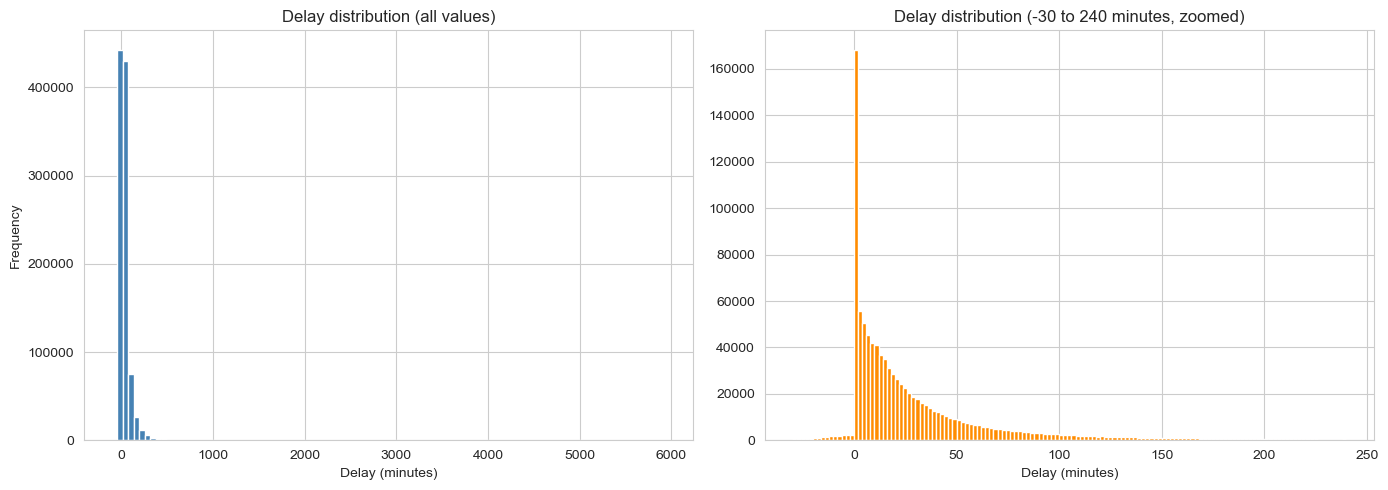

In [43]:
sample = clean["delay"].sample(1_000_000, random_state=42)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].hist(sample, bins=100, color="steelblue")
ax[0].set_title("Delay distribution (all values)")
ax[0].set_xlabel("Delay (minutes)"); ax[0].set_ylabel("Frequency")

ax[1].hist(sample[(sample >= -30) & (sample <= 240)], bins=135, color="darkorange")
ax[1].set_title("Delay distribution (-30 to 240 minutes, zoomed)")
ax[1].set_xlabel("Delay (minutes)")
plt.tight_layout(); plt.show()

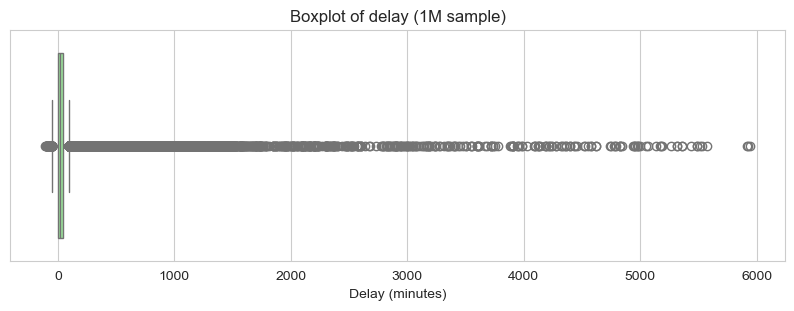

In [45]:
plt.figure(figsize=(10, 3))
sns.boxplot(x=sample, color="lightgreen")
plt.title("Boxplot of delay (1M sample)")
plt.xlabel("Delay (minutes)")
plt.show()

,count,mean,median,std
type_code,,,,
PRM-TRAINS,152768,97.660004,20.0,193.809998
GRB-TRAINS,94651,52.400002,17.0,111.800003
SF-TRAINS,4850024,44.160000,17.0,91.330002
EXP-TRAINS,13075129,37.680000,18.0,75.449997
PASS-TRAINS,17801507,34.160000,14.0,94.029999
RAJ-TRAINS,126130,31.730000,10.0,86.989998
SHT-TRAINS,112870,15.250000,6.0,47.840000
T18-TRAINS,341344,14.390000,6.0,37.750000


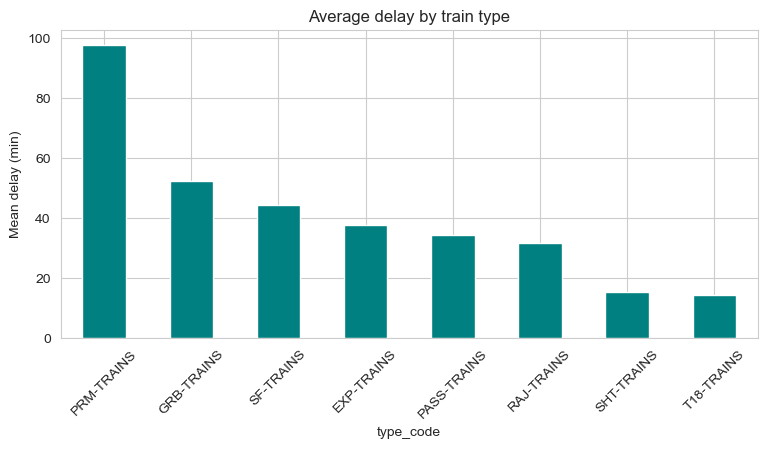

In [47]:
by_type = (clean.groupby("type_code", observed=True)["delay"]
           .agg(["count", "mean", "median", "std"]).round(2)
           .sort_values("mean", ascending=False))
display(by_type)

by_type["mean"].plot(kind="bar", figsize=(9, 4), color="teal")
plt.title("Average delay by train type"); plt.ylabel("Mean delay (min)")
plt.xticks(rotation=45); plt.show()

,count,mean,median
month,,,
2025-02,1944680,43.570000,16.0
2025-03,3016924,36.000000,15.0
2025-04,3007694,32.740002,14.0
2025-05,3119964,37.090000,15.0
2025-06,3022503,35.060001,15.0
2025-07,3129277,33.790001,15.0
2025-08,3142091,31.520000,14.0
2025-09,3070961,32.419998,14.0
2025-10,3171871,35.820000,16.0


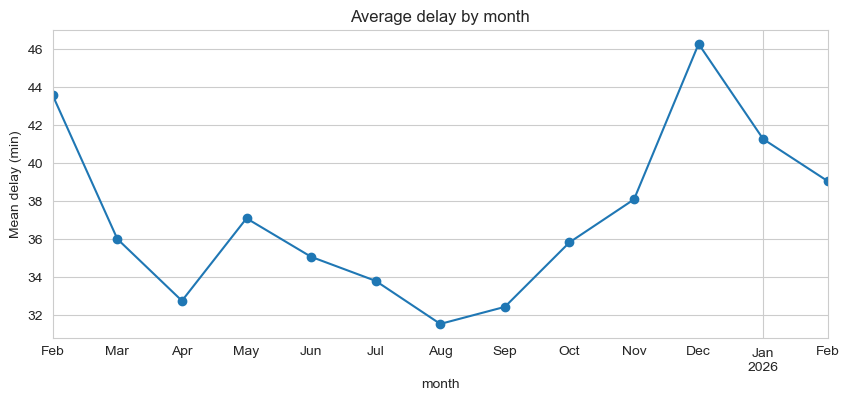

,count,mean,median
weekday,,,
Monday,5257819,37.139999,16.0
Tuesday,5212559,36.270000,16.0
Wednesday,5216223,36.450001,16.0
Thursday,5243282,37.480000,16.0
Friday,5270172,37.310001,16.0
Saturday,5280019,36.910000,16.0
Sunday,5074349,36.049999,15.0


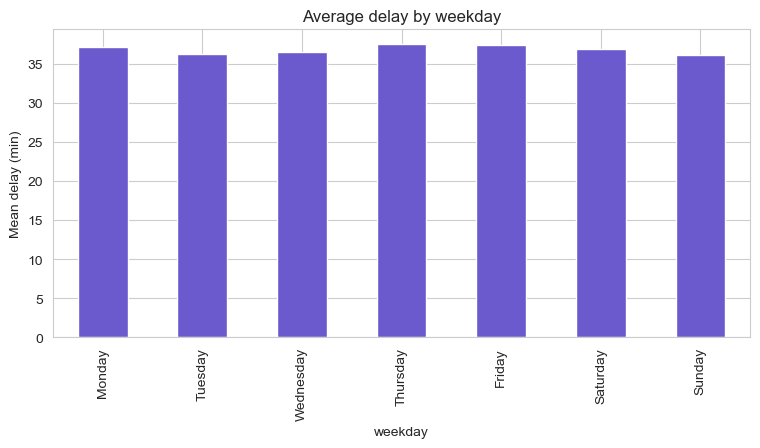

In [49]:
clean["month"] = clean["date"].dt.to_period("M")
clean["weekday"] = clean["date"].dt.day_name()

monthly = clean.groupby("month")["delay"].agg(["count", "mean", "median"]).round(2)
display(monthly)
monthly["mean"].plot(marker="o", figsize=(10, 4))
plt.title("Average delay by month"); plt.ylabel("Mean delay (min)"); plt.show()

order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
wk = clean.groupby("weekday")["delay"].agg(["count", "mean", "median"]).reindex(order).round(2)
display(wk)
wk["mean"].plot(kind="bar", figsize=(9, 4), color="slateblue")
plt.title("Average delay by weekday"); plt.ylabel("Mean delay (min)"); plt.show()

In [51]:
tr = clean.groupby("train_no")["delay"].agg(["count", "mean"])
display(tr[tr["count"] >= 1000].sort_values("mean", ascending=False).head(15).round(2))

st = clean.groupby("station_name", observed=True)["delay"].agg(["count", "mean"])
display(st[st["count"] >= 1000].sort_values("mean", ascending=False).head(15).round(2))

,count,mean
train_no,,
68006,6553,597.000000
68014,6709,596.210022
68012,1530,581.450012
2863,1172,573.549988
2864,1172,572.429993
12950,1924,546.010010
7030,1954,517.940002
8611,1486,491.109985
9452,1728,456.290009


,count,mean
station_name,,
NPTY,1285,424.880005
KSO,4539,281.679993
CHGA,2115,277.600006
KKQ,4539,275.170013
GII,4042,274.250000
KATB,4008,273.320007
SUA,4857,257.799988
KNM,4008,254.029999
DKU,1436,249.970001


In [53]:
train_details = pd.read_csv(r"D:\Indian_Railway_Delay_Project\data\train_details.csv")
names = train_details.drop_duplicates("train_no").set_index("train_no")["train_name"]

top_trains = [68006, 68014, 68012, 2863, 2864, 12950, 7030, 8611, 9452, 68176]
types = clean.drop_duplicates("train_no").set_index("train_no")["type_code"]

for t in top_trains:
    x = clean[clean["train_no"] == t]["delay"]
    print(f"{t} | {names.get(t)} | {types.get(t)} | records={len(x)} | "
          f"mean={x.mean():.0f} | median={x.median():.0f} | "
          f"25%={x.quantile(.25):.0f} | 75%={x.quantile(.75):.0f}")

68006 | TATA KGP MEMU | PASS-TRAINS | records=6553 | mean=597 | median=18 | 25%=0 | 75%=643
68014 | TATA KGP MEMU | PASS-TRAINS | records=6709 | mean=596 | median=57 | 25%=4 | 75%=662
68012 | TATA KGP MEMU | PASS-TRAINS | records=1530 | mean=581 | median=10 | 25%=0 | 75%=58
2863 | SRC YNK SPL | SF-TRAINS | records=1172 | mean=574 | median=535 | 25%=281 | 75%=825
2864 | YNK SRC SPL | EXP-TRAINS | records=1172 | mean=572 | median=526 | 25%=192 | 75%=875
12950 | PBR KAVIGURU EXP | SF-TRAINS | records=1924 | mean=546 | median=568 | 25%=380 | 75%=702
7030 | SC AGTL SPL | EXP-TRAINS | records=1954 | mean=518 | median=489 | 25%=275 | 75%=738
8611 | SRC AII SPL | EXP-TRAINS | records=1486 | mean=491 | median=450 | 25%=289 | 75%=620
9452 | BGP GIMB SPL | EXP-TRAINS | records=1728 | mean=456 | median=497 | 25%=290 | 75%=610
68176 | VZR ROP MEMU | PASS-TRAINS | records=2817 | mean=443 | median=1 | 25%=0 | 75%=479


In [55]:
stations = pd.read_csv(r"D:\Indian_Railway_Delay_Project\data\station_full_names.csv")
top_st = ["NPTY","KSO","CHGA","KKQ","GII","KATB","SUA","KNM","DKU","KKPR"]
display(stations[stations["station_name"].isin(top_st)]
        [["station_name", "station_full_name", "station_zone"]])
print("Not in station file:", [s for s in top_st if s not in set(stations["station_name"])])

,station_name,station_full_name,station_zone
1639,CHGA,CHIRUGODA,SER
2161,DKU,DUMRI KHURD,SECR
2697,GII,GIDHNI,SER
3734,KATB,KHATKURA P H,SER
4068,KKPR,KOKPARA,SER
4069,KKQ,KALAIKUNDA,SER
4236,KNM,KANIMAHULI P H,SER
4460,KSO,KHEMASULI PH,SER
6024,NPTY,NIMPURA TH YARD,SER
7967,SUA,SARDIHA,SER


Not in station file: []


Rows with unknown zone: 53256


,count,mean,median
zone,,,
SCOR,46,97.779999,44.5
SER,1534101,68.029999,18.0
SECR,1305622,60.029999,30.0
ECR,3853551,52.900002,29.0
ECOR,1419314,51.630001,31.0
NER,1948670,46.490002,16.0
KR,235478,46.099998,33.0
NCR,1541599,46.080002,24.0
WCR,1405583,45.630001,22.0


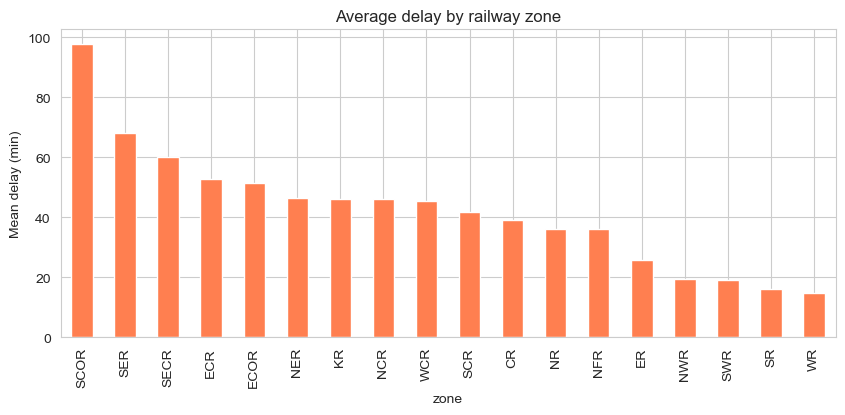

In [57]:
zone_map = stations.set_index("station_name")["station_zone"]
clean["zone"] = clean["station_name"].map(zone_map)

print("Rows with unknown zone:", clean["zone"].isna().sum())
zone_stats = (clean.groupby("zone", observed=True)["delay"]
              .agg(["count", "mean", "median"]).round(2)
              .sort_values("mean", ascending=False))
display(zone_stats)
zone_stats["mean"].plot(kind="bar", figsize=(10, 4), color="coral")
plt.title("Average delay by railway zone"); plt.ylabel("Mean delay (min)")
plt.show()

In [59]:
t = clean[clean["train_no"] == 68006]

# Pattern by month
display(t.groupby(t["date"].dt.to_period("M"))["delay"]
        .agg(["count", "mean", "median"]).round(1))

# # Most-delayed date and least-delayed date
day_mean = t.groupby("date")["delay"].mean().sort_values()
worst_date, best_date = day_mean.index[-1], day_mean.index[0]

for dt in [worst_date, best_date]:
    print("\nDate:", dt.date())
    display(t[t["date"] == dt].sort_values("station_no")
            [["station_no", "station_name", "delay"]])

,count,mean,median
date,,,
2025-02,441,1069.599976,8.0
2025-03,615,467.200012,32.0
2025-04,630,623.900024,6.5
2025-05,651,436.500000,10.0
2025-06,630,780.900024,8.0
2025-07,625,840.200012,11.0
2025-08,589,542.900024,49.0
2025-09,570,177.100006,29.0
2025-10,589,371.899994,7.0



Date: 2025-02-28


,station_no,station_name,delay
33300952,1,TATA,0.0
33301317,2,SLJR,0.0
33301682,3,GVDP,0.0
33302047,4,ASB,16.0
33302412,5,RHE,5705.0
33302777,6,GUD,5662.0
33303142,7,GTS,5661.0
33303507,8,CHGA,5660.0
33303872,9,DVM,5659.0
33304237,10,KKPR,5659.0



Date: 2025-10-10


,station_no,station_name,delay
33301176,1,TATA,5.0
33301906,3,GVDP,3.0
33302271,4,ASB,3.0
33302636,5,RHE,0.0
33303001,6,GUD,0.0
33303366,7,GTS,0.0
33303731,8,CHGA,0.0
33304096,9,DVM,0.0
33304461,10,KKPR,0.0
33304826,11,CKU,0.0


In [61]:
suspect = [68006, 68014, 68012, 68176]
is_s = clean["train_no"].isin(suspect)
big = clean["delay"] > 360
ser = clean["zone"] == "SER"

print("Rows of these 4 trains:", is_s.sum(), "=", round(is_s.mean()*100, 3), "%")
print("Mean delay overall          :", round(clean["delay"].mean(), 2))
print("Mean delay without them     :", round(clean.loc[~is_s, "delay"].mean(), 2))
print("SER mean overall            :", round(clean.loc[ser, "delay"].mean(), 2))
print("SER mean without them       :", round(clean.loc[ser & ~is_s, "delay"].mean(), 2))

tail = clean.loc[big, "train_no"].value_counts()
print("\nDelays > 360 min, total     :", big.sum())
print("From these 4 trains         :", (big & is_s).sum())
print("Distinct trains with >360   :", len(tail))
print("Top 10 trains' share of >360:", round(tail.head(10).sum() / big.sum() * 100, 1), "%")

Rows of these 4 trains: 17609 = 0.048 %
Mean delay overall          : 36.81
Mean delay without them     : 36.55
SER mean overall            : 68.03
SER mean without them       : 62.19

Delays > 360 min, total     : 271752
From these 4 trains         : 4841
Distinct trains with >360   : 3498
Top 10 trains' share of >360: 10.6 %


## PHASE 4: OUTLIER ANALYSIS
**What we do:** check how extreme delays are, test IQR limits and percentile caps, and find journeys with impossible jumps between consecutive stops.
**Result:** 4,084 journeys (0.20% of rows) with a jump over 1,000 minutes were removed, and a capped copy of the delay (99th percentile) was kept for comparison.

In [63]:
d = clean["delay"]
q1, q3 = d.quantile(0.25), d.quantile(0.75)
iqr = q3 - q1
low, high = q1 - 1.5*iqr, q3 + 1.5*iqr
print("Q1, Q3, IQR :", q1, q3, iqr)
print("IQR limits  :", low, "to", high)
print("Below lower :", (d < low).sum(), round((d < low).mean()*100, 2), "%")
print("Above upper :", (d > high).sum(), round((d > high).mean()*100, 2), "%")

for p in [0.99, 0.995, 0.999]:
    cap = d.quantile(p)
    print(f"{p*100:.1f}th percentile = {cap:.0f} min | records above: {(d > cap).sum()}")

Q1, Q3, IQR : 4.0 41.0 37.0
IQR limits  : -51.5 to 96.5
Below lower : 8302 0.02 %
Above upper : 3235378 8.85 %
99.0th percentile = 315 min | records above: 365087
99.5th percentile = 431 min | records above: 182419
99.9th percentile = 872 min | records above: 36497


In [65]:
# Small DataFrame only, to save memory
tmp = clean[["train_no", "date", "station_no", "delay"]].sort_values(
    ["train_no", "date", "station_no"]).reset_index(drop=True)

same_journey = (tmp["train_no"].eq(tmp["train_no"].shift()) &
                tmp["date"].eq(tmp["date"].shift()))
tmp["jump"] = (tmp["delay"] - tmp["delay"].shift()).where(same_journey)

# How big are typical jumps?
print(tmp["jump"].abs().describe(percentiles=[.5, .9, .99, .999]).round(1))

for lim in [200, 500, 1000, 2000]:
    print(f"Jumps bigger than {lim} min:", (tmp['jump'].abs() > lim).sum())

count    34692982.0
mean            8.3
std            32.5
min             0.0
50%             3.0
90%            22.0
99%            64.0
99.9%         150.0
max          6877.0
Name: jump, dtype: float64
Jumps bigger than 200 min: 19275
Jumps bigger than 500 min: 7459
Jumps bigger than 1000 min: 4506
Jumps bigger than 2000 min: 2111


In [67]:
tmp["big_jump"] = tmp["jump"].abs() > 1000

# Does each journey contain at least one big jump?
jflag = tmp.groupby(["train_no", "date"])["big_jump"].any().rename("journey_has_jump")
tmp = tmp.join(jflag, on=["train_no", "date"])

tail = tmp["delay"] > 360
print("Records > 360 min                 :", tail.sum())
print("  of these, in jump journeys      :", (tail & tmp["journey_has_jump"]).sum())
print("  share (%)                       :",
      round((tail & tmp["journey_has_jump"]).sum() / tail.sum() * 100, 1))
print("Journeys with a big jump          :", jflag.sum(), "of", len(jflag))

Records > 360 min                 : 271752
  of these, in jump journeys      : 19060
  share (%)                       : 7.0
Journeys with a big jump          : 4084 of 1861441


In [69]:
keys = [tmp["train_no"], tmp["date"]]
sizes  = tmp.groupby(keys).size()
tail_n = (tmp["delay"] > 360).groupby(keys).sum()

print("Total journeys:", len(sizes), "| Total rows:", sizes.sum())
for lim in [200, 500, 1000, 2000]:
    f = (tmp["jump"].abs() > lim).groupby(keys).any()
    rows_f = sizes[f].sum()
    print(f"limit {lim:>5}: journeys flagged = {f.sum():>6} | "
          f"rows in them = {rows_f:>8} ({rows_f/sizes.sum()*100:.2f}%) | "
          f"tail (>360) rows in them = {tail_n[f].sum():>7}")

Total journeys: 1861441 | Total rows: 36554423
limit   200: journeys flagged =  16008 | rows in them =   354772 (0.97%) | tail (>360) rows in them =   77355
limit   500: journeys flagged =   6537 | rows in them =   126001 (0.34%) | tail (>360) rows in them =   36345
limit  1000: journeys flagged =   4084 | rows in them =    73678 (0.20%) | tail (>360) rows in them =   19060
limit  2000: journeys flagged =   2004 | rows in them =    34274 (0.09%) | tail (>360) rows in them =    8718


In [71]:
f = (tmp["jump"].abs() > 1000).groupby(keys).any()
flagged = f[f].reset_index()[["train_no", "date"]]

print("Upward jumps > 1000  :", (tmp["jump"] > 1000).sum())
print("Downward jumps < -1000:", (tmp["jump"] < -1000).sum())
print("Distinct trains flagged:", flagged["train_no"].nunique())

print("\nTrains with the most flagged journeys:")
display(flagged["train_no"].value_counts().head(10))

print("Flagged journeys by month:")
display(flagged["date"].dt.to_period("M").value_counts().sort_index())

Upward jumps > 1000  : 4121
Downward jumps < -1000: 385
Distinct trains flagged: 1159

Trains with the most flagged journeys:


train_no
68006    124
68014    111
68755     86
68102     83
68016     74
68176     62
68174     60
78814     58
68809     50
68813     50
Name: count, dtype: int64

Flagged journeys by month:


date
2025-02    260
2025-03    376
2025-04    374
2025-05    385
2025-06    323
2025-07    297
2025-08    297
2025-09    291
2025-10    334
2025-11    289
2025-12    366
2026-01    403
2026-02     89
Freq: M, Name: count, dtype: int64

In [73]:
import pandas as pd, numpy as np

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

# Free memory from earlier cells (ignore if tmp doesn't exist)
try:
    del tmp
except NameError:
    pass

# 0. Reload the Phase 2 clean file
clean = pd.read_pickle(r"D:\Indian_Railway_Delay_Project\delay_clean.pkl")
print("Start rows:", len(clean))                       # expect 36,554,423

# 1. Sort so consecutive rows = consecutive stops of the same journey
clean = clean.sort_values(["train_no", "date", "station_no"]).reset_index(drop=True)

# 2. Jump between consecutive stops of the same journey
same_journey = (clean["train_no"].eq(clean["train_no"].shift()) &
                clean["date"].eq(clean["date"].shift()))
jump = (clean["delay"] - clean["delay"].shift()).where(same_journey)

# 3. Flag every row whose journey contains a jump bigger than 1000 min
JUMP_LIMIT = 1000
big = jump.abs() > JUMP_LIMIT
journey_id = clean.groupby(["train_no", "date"]).ngroup()
bad_ids = journey_id[big].unique()
is_bad = journey_id.isin(bad_ids)
print("Journeys flagged:", len(bad_ids))               # expect 4,084
print("Rows flagged    :", is_bad.sum())               # expect 73,678

# 4. Save the removed rows (for the report), then remove them
clean.loc[is_bad, ["train_no", "date", "station_no", "station_name", "delay"]] \
     .to_pickle(r"D:\Indian_Railway_Delay_Project\removed_jump_rows.pkl")

clean2 = clean.loc[~is_bad].reset_index(drop=True)
del clean, jump, big, journey_id, is_bad, same_journey
print("Rows after removal:", len(clean2))              # expect 36,480,745

# 5. Capped copy of the target (raw delay is kept as well)
cap = float(clean2["delay"].quantile(0.99))
clean2["delay_capped"] = clean2["delay"].clip(upper=cap).astype("float32")
print("99th percentile cap:", cap)                     # should be close to 315
print("Rows capped        :", (clean2["delay"] > cap).sum())

# 6. Compare raw and capped, then save
display(clean2[["delay", "delay_capped"]].describe().round(2))
print("Skewness raw   :", round(clean2["delay"].skew(), 2))
print("Skewness capped:", round(clean2["delay_capped"].skew(), 2))

clean2.to_pickle(r"D:\Indian_Railway_Delay_Project\delay_clean_v2.pkl")
print("Saved delay_clean_v2.pkl")

Start rows: 36554423
Journeys flagged: 4084
Rows flagged    : 73678
Rows after removal: 36480745
99th percentile cap: 308.0
Rows capped        : 364148


,delay,delay_capped
count,36480745.00,36480745.00
mean,35.63,33.91
std,62.54,48.60
min,-120.00,-120.00
25%,4.00,4.00
50%,16.00,16.00
75%,40.00,40.00
max,5013.00,308.00


Skewness raw   : 6.51
Skewness capped: 2.94
Saved delay_clean_v2.pkl


## PHASE 5: CORRELATION ANALYSIS
A. What are we doing?

Measuring which numeric variables move together with delay, and with each other. For categorical ones (train, station, type, zone, month) we measure how much of the delay variation their groups explain.

### B. Why?
It shows which features have any relationship with delay before we build the model.
It shows redundant features, like station_no and distance_from_origin, which would confuse Linear Regression.
It sets honest expectations: for one feature, the model's R² equals r², so a correlation of 0.2 means about 4% explained.

### C. Concepts
Correlation (r): from -1 to +1, showing direction and strength of a relationship. Rough guide: below 0.1 negligible, 0.1 to 0.3 weak, 0.3 to 0.5 moderate, above 0.5 strong.
Pearson: measures only a straight-line relationship, and is sensitive to extreme values.
Spearman: works on ranks, so it catches any consistently rising or falling relationship and is not affected by the tail or capping.


Limits of correlation:
It misses curved patterns. Delay is high in winter and low mid-year, so month number can show a near-zero correlation although month matters.
It does not mean cause.
With 36 million rows even tiny correlations are "significant", so look at the size, not at p-values.


Multicollinearity: two input features strongly correlated with each other. The model can't tell their effects apart and its coefficients become unstable.
Correlation ratio (eta²): for categories. It is the share of delay variance explained by the group averages (0% to 100%).
ID columns: train number is a label, so numeric correlation with it is meaningless. We use eta² for it instead.

In [77]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
sns.set_style("whitegrid")

DATA = r"D:\Indian_Railway_Delay_Project\data"
clean2 = pd.read_pickle(r"D:\Indian_Railway_Delay_Project\delay_clean_v2.pkl")
print(clean2.shape)

# Random sample: correlations from 2M rows are as reliable as from 36M
s = clean2.sample(2_000_000, random_state=42).copy()

# Schedule: convert "HH:MM" text to numbers
schedule = pd.read_csv(DATA + r"\combined_schedule.csv")
print("Duplicate (train_no, station_no) in schedule:",
      schedule.duplicated(["train_no", "station_no"]).sum())   # must be 0

def to_minutes(t):
    hm = t.str.split(":", expand=True).astype(float)
    return hm[0] * 60 + hm[1]

arr = to_minutes(schedule["arrival_time"])
dep = to_minutes(schedule["departure_time"])
schedule["sched_hour"] = (arr.fillna(dep) // 60)     # origin stop uses departure time

# Merge on BOTH keys (station_no restarts for every train)
s["train_no"]   = s["train_no"].astype("int64")
s["station_no"] = s["station_no"].astype("int64")
s = s.merge(schedule[["train_no", "station_no", "distance_from_origin",
                      "arrival_day", "sched_hour"]],
            on=["train_no", "station_no"], how="left")
print("Rows after merge:", len(s))                    # must be 2,000,000
print("Rows with no schedule match:", s["distance_from_origin"].isna().sum())

# Numeric date features
s["month_num"]   = s["date"].dt.month
s["weekday_num"] = s["date"].dt.dayofweek             # 0 = Monday
s["day_of_year"] = s["date"].dt.dayofyear

(36480745, 8)
Duplicate (train_no, station_no) in schedule: 0
Rows after merge: 2000000
Rows with no schedule match: 52817


In [79]:
feat = ["station_no", "distance_from_origin", "arrival_day", "sched_hour",
        "month_num", "weekday_num", "day_of_year"]

res = pd.DataFrame({
    "pearson_raw_delay":    s[feat].corrwith(s["delay"]),
    "pearson_capped_delay": s[feat].corrwith(s["delay_capped"]),
    "spearman_delay":       s[feat].corrwith(s["delay"], method="spearman"),
}).round(3)
display(res)

,pearson_raw_delay,pearson_capped_delay,spearman_delay
station_no,0.209,0.242,0.291
distance_from_origin,0.232,0.241,0.281
arrival_day,0.172,0.179,0.134
sched_hour,0.027,0.035,0.044
month_num,0.001,0.004,0.005
weekday_num,0.002,0.002,0.003
day_of_year,0.002,0.004,0.005


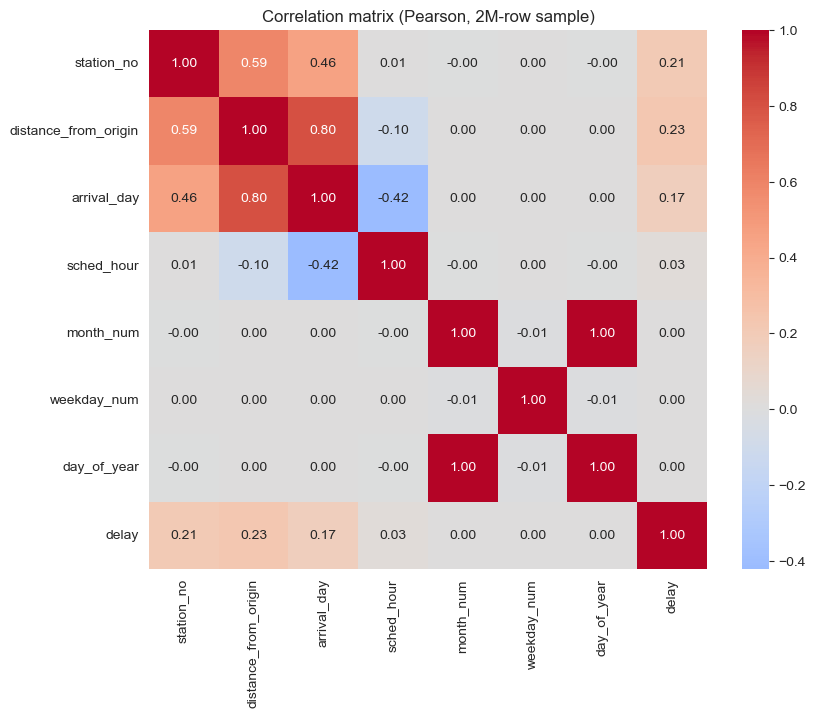

In [81]:
corr = s[feat + ["delay"]].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix (Pearson, 2M-row sample)")
plt.savefig(r"D:\Indian_Railway_Delay_Project\graph_correlation_heatmap.png",
            dpi=150, bbox_inches="tight")
plt.show()

In [83]:
def eta_squared(target, key):
    grand = target.mean()
    grp = target.groupby(key, observed=True).agg(["count", "mean"])
    ss_between = (grp["count"] * (grp["mean"] - grand) ** 2).sum()
    ss_total = ((target - grand) ** 2).sum()
    return ss_between / ss_total

y_raw = clean2["delay"].astype("float64")
y_cap = clean2["delay_capped"].astype("float64")
zone_map = pd.read_csv(DATA + r"\station_full_names.csv") \
             .set_index("station_name")["station_zone"]

keys = {
    "train_no":     clean2["train_no"],
    "station_name": clean2["station_name"],
    "type_code":    clean2["type_code"],
    "zone":         clean2["station_name"].map(zone_map),
    "month":        clean2["date"].dt.to_period("M"),
    "weekday":      clean2["date"].dt.dayofweek,
}

rows = []
for name, key in keys.items():
    rows.append((name, key.nunique(),
                 round(eta_squared(y_raw, key) * 100, 2),
                 round(eta_squared(y_cap, key) * 100, 2)))
display(pd.DataFrame(rows, columns=["variable", "groups",
                                    "explained_%_raw", "explained_%_capped"]))

,variable,groups,explained_%_raw,explained_%_capped
0,train_no,7032,28.74,31.95
1,station_name,8222,10.69,14.70
2,type_code,8,0.88,0.70
3,zone,18,4.36,6.07
4,month,13,0.41,0.48
5,weekday,7,0.00,0.01


In [85]:
# clean2 is still sorted by train, date, station_no (done in Cell 4.6)
same_journey = (clean2["train_no"].eq(clean2["train_no"].shift()) &
                clean2["date"].eq(clean2["date"].shift()))
prev = clean2["delay"].shift().where(same_journey)
ok = prev.notna()
print("Stop pairs:", ok.sum())
print("Pearson  corr(delay, previous-stop delay):",
      round(clean2.loc[ok, "delay"].corr(prev[ok]), 3))

idx = ok[ok].sample(2_000_000, random_state=42).index
print("Spearman corr (2M pairs)                 :",
      round(clean2.loc[idx, "delay"].corr(prev.loc[idx], method="spearman"), 3))

Stop pairs: 34623388
Pearson  corr(delay, previous-stop delay): 0.965
Spearman corr (2M pairs)                 : 0.833


## PHASE 6: PRE-MODELLING CHECKS AND SPLIT DESIGN
#### A. What are we doing?

Three checks before building the model table:

Why 2.62% of rows don't match the schedule.
Whether extreme delays remain after the jump removal.
How to split the data by time, and how many test trains and stations were never seen in training.
#### B. Why?
Unmatched rows would silently get missing distance values, and Linear Regression can't take missing values.
A max of 5,013 min with skewness still at 6.51 means the tail may still hold bad records that distort squared error.
A random split would let the model see the future. Delays are time-ordered, so the test set must come after the training set, otherwise the score is too optimistic.
Encoding train and station depends on how many are new in the test period.
#### C. Concepts
Data leakage: the model uses information that wouldn't be available at prediction time (previous-stop delay) or sees test data during training.
Time-based split: train on earlier dates, test on later ones, which mimics real use.
One-hot encoding: one 0/1 column per category. For train_no that means about 7,000 columns.
Target (mean) encoding: replace a category with its average delay. It must be computed on training data only, otherwise test answers leak in.
Unseen categories: a test train or station absent from training. The model has no history for it, so we need a fallback such as the overall mean.
VIF (variance inflation factor): a number showing how strongly one feature is explained by the others. It is used to check multicollinearity later.

In [88]:
import pandas as pd, numpy as np
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

DATA = r"D:\Indian_Railway_Delay_Project\data"
clean2 = pd.read_pickle(r"D:\Indian_Railway_Delay_Project\delay_clean_v2.pkl")
schedule = pd.read_csv(DATA + r"\combined_schedule.csv")

# All distinct (train, stop) pairs in the delay data, with row counts
pairs = (clean2.groupby(["train_no", "station_no"], observed=True)
               .size().rename("rows").reset_index())
pairs["train_no"] = pairs["train_no"].astype("int64")
pairs["station_no"] = pairs["station_no"].astype("int64")

sched_keys = schedule[["train_no", "station_no"]].drop_duplicates()
m = pairs.merge(sched_keys, on=["train_no", "station_no"],
                how="left", indicator=True)
miss = m[m["_merge"] == "left_only"]

print("Distinct pairs:", len(m), "| unmatched pairs:", len(miss))
print("Rows in unmatched pairs:", miss["rows"].sum(),
      "=", round(miss["rows"].sum() / m["rows"].sum() * 100, 2), "%")

no_sched = ~miss["train_no"].isin(schedule["train_no"])
print("\nTrain absent from schedule : pairs", no_sched.sum(),
      "| rows", miss.loc[no_sched, "rows"].sum())
print("Train in schedule, stop missing: pairs", (~no_sched).sum(),
      "| rows", miss.loc[~no_sched, "rows"].sum())

by_train = miss.groupby("train_no")["rows"].sum().sort_values(ascending=False)
print("\nTrains with any unmatched stop:", len(by_train))
display(by_train.head(10))

# For trains present in the schedule: compare highest stop number
sched_max = schedule.groupby("train_no")["station_no"].max()
data_max = m.groupby("train_no")["station_no"].max()
chk = pd.DataFrame({"data_max_stop": data_max, "sched_max_stop": sched_max})
display(chk.loc[by_train.index[:10]])

Distinct pairs: 146705 | unmatched pairs: 5559
Rows in unmatched pairs: 956613 = 2.62 %

Train absent from schedule : pairs 332 | rows 68368
Train in schedule, stop missing: pairs 5227 | rows 888245

Trains with any unmatched stop: 2044


train_no
15013    13750
19223     6435
20503     6264
20504     6264
7282      6171
52475     5841
52476     5532
19110     5475
18525     4329
68403     4024
Name: rows, dtype: int64

,data_max_stop,sched_max_stop
train_no,,
15013,47.0,NaN
19223,53.0,35.0
20503,25.0,NaN
20504,24.0,NaN
7282,21.0,4.0
52475,28.0,9.0
52476,28.0,9.0
19110,57.0,42.0
18525,36.0,12.0


In [90]:
hi = clean2[clean2["delay"] > 1000]
print("Rows > 1000 min:", len(hi), "| > 2000 min:", (hi["delay"] > 2000).sum())

jid = hi.groupby(["train_no", "date"], observed=True).ngroup()
print("Journeys containing a row > 1000:", jid.nunique())

# Is the very first recorded stop of a journey already huge? (no jump to detect)
first = clean2.groupby(["train_no", "date"], observed=True)["delay"].first()
print("Journeys whose first recorded delay > 1000:", (first > 1000).sum(),
      "of", len(first))

print("\nTrains with most rows > 1000:")
display(hi["train_no"].value_counts().head(10))

Rows > 1000 min: 9588 | > 2000 min: 497
Journeys containing a row > 1000: 944
Journeys whose first recorded delay > 1000: 188 of 1857357

Trains with most rows > 1000:


train_no
15483    350
12130    345
20821    309
15484    279
2864     207
18030    199
4152     181
18478    179
2863     168
2570     152
Name: count, dtype: int64

In [92]:
mon = clean2["date"].dt.to_period("M")
display(clean2.groupby(mon)["delay"].agg(["count", "mean", "median"]).round(1))

tr = clean2["date"] < "2025-11-01"     # train: Feb-Oct 2025
va = (clean2["date"] >= "2025-11-01") & (clean2["date"] < "2025-12-01")  # validation: Nov 2025
te = clean2["date"] >= "2025-12-01"    # test: Dec 2025 - Feb 2026
print("Train / Validation / Test rows:", tr.sum(), va.sum(), te.sum())

seen_tr = set(clean2.loc[tr, "train_no"].unique())
seen_st = set(clean2.loc[tr, "station_name"].unique())
print("Test rows with a train never seen in training  :",
      (~clean2.loc[te, "train_no"].isin(seen_tr)).sum())
print("Test rows with a station never seen in training:",
      (~clean2.loc[te, "station_name"].isin(seen_st)).sum())

for name, mask in [("train", tr), ("validation", va), ("test", te)]:
    print(f"Mean delay ({name}):", round(clean2.loc[mask, "delay"].mean(), 2),
          "| mean capped:", round(clean2.loc[mask, "delay_capped"].mean(), 2))

,count,mean,median
date,,,
2025-02,1939783,41.799999,16.0
2025-03,3009933,34.299999,15.0
2025-04,3000640,31.200001,14.0
2025-05,3113223,35.799999,15.0
2025-06,3016893,34.000000,15.0
2025-07,3124031,32.900002,15.0
2025-08,3136915,30.799999,14.0
2025-09,3065212,31.400000,14.0
2025-10,3165690,34.700001,16.0


Train / Validation / Test rows: 26572320 3052319 6856106
Test rows with a train never seen in training  : 32257
Test rows with a station never seen in training: 4690
Mean delay (train): 33.77 | mean capped: 32.14
Mean delay (validation): 37.11 | mean capped: 35.72
Mean delay (test): 42.2 | mean capped: 39.95


## PHASE 7: MODEL TABLE AND BASELINE LINEAR REGRESSION
#### A. What are we doing?

Building the table the model will use and fitting the first Linear Regression models, compared against trivial baselines.

#### B. Why?

Without baselines a score means nothing. An R² of 0.15 may be good or bad depending on what "always predict the average" achieves. Adding features step by step also shows what each group of information contributes.

#### C. Concepts
Baseline model: predicts one constant (training mean or median) and sets the floor.
MAE: the average size of the error in minutes. It is robust to the tail.
RMSE: like MAE but squares errors first, so big misses weigh more.
R²: the share of variance explained. On a shifted test period a constant model can score slightly below 0.


Bias (mean error): the average of prediction − actual. Negative means under-prediction.
Target encoding with smoothing: replace a category with its average delay, pulled toward the overall mean when the category has few rows: (n × category mean + K × overall mean) ÷ (n + K), with K = 20. It is computed on training rows only, otherwise test answers leak in.


Why a 3M sample is enough to fit: we estimate about 7 coefficients. With 3 million rows the estimates are extremely stable, and predictions are made for every validation and test row.

In [96]:
sched_cols = schedule.columns.tolist()
print("Schedule columns:", sched_cols)

t = 19223
d_stops = (clean2.loc[clean2["train_no"] == t, ["station_no", "station_name"]]
                 .drop_duplicates().sort_values("station_no"))
s_stops = schedule.loc[schedule["train_no"] == t].sort_values("station_no")
print("\nTrain", t, "| stops in delay data:", len(d_stops),
      "| stops in schedule:", len(s_stops))
print("\nDelay data, stops 28 to 40:")
display(d_stops[d_stops["station_no"].between(28, 40)])
print("Schedule, last 8 rows:")
display(s_stops.tail(8))

Schedule columns: ['station_no', 'station_name', 'distance_from_origin', 'arrival_day', 'arrival_time', 'departure_day', 'departure_time', 'train_no']

Train 19223 | stops in delay data: 53 | stops in schedule: 35

Delay data, stops 28 to 40:


,station_no,station_name
15895921,28,SGRA
15895922,29,MBY
15895923,30,BTI
15895924,31,GNA
15895925,32,GJUT
15895926,33,KKP
15895927,34,FDK
15895928,35,FZR
15895929,36,MWX
15895930,37,MXH


Schedule, last 8 rows:


,station_no,station_name,distance_from_origin,arrival_day,arrival_time,departure_day,departure_time,train_no
75511,28,SGRA,1007,2,04:48,2,04:50,19223
75512,29,MBY,1037,2,05:10,2,05:15,19223
75513,30,BTI,1073,2,07:30,2,07:45,19223
75514,31,GNA,1085,2,07:57,2,07:59,19223
75515,32,GJUT,1099,2,08:12,2,08:14,19223
75516,33,KKP,1116,2,08:29,2,08:31,19223
75517,34,FDK,1128,2,08:53,2,08:55,19223
75518,35,FZR,1160,2,09:30,2,NaN,19223


In [98]:
import pandas as pd, numpy as np
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

DATA = r"D:\Indian_Railway_Delay_Project\data"
clean2 = pd.read_pickle(r"D:\Indian_Railway_Delay_Project\delay_clean_v2.pkl")
schedule = pd.read_csv(DATA + r"\combined_schedule.csv")

def to_minutes(t):
    hm = t.str.split(":", expand=True).astype(float)
    return hm[0] * 60 + hm[1]

arr = to_minutes(schedule["arrival_time"])
dep = to_minutes(schedule["departure_time"])
schedule["sched_hour"] = arr.fillna(dep) // 60

# One integer key per (train, stop). Stop numbers are below 1000.
print("Max station_no in schedule:", schedule["station_no"].max())
schedule["key"] = (schedule["train_no"].astype("int64") * 1000
                   + schedule["station_no"].astype("int64"))
assert schedule["key"].is_unique
look = schedule.set_index("key")

key = (clean2["train_no"].astype("int64") * 1000
       + clean2["station_no"].astype("int64"))

base = pd.DataFrame({
    "date":         clean2["date"],
    "train_no":     clean2["train_no"].astype("int64"),
    "station_name": clean2["station_name"],
    "station_no":   clean2["station_no"].astype("int16"),
    "dist":         key.map(look["distance_from_origin"]).astype("float32"),
    "hour":         key.map(look["sched_hour"]).astype("float32"),
    "delay":        clean2["delay"].astype("float32"),
    "cap":          clean2["delay_capped"].astype("float32"),
})
del clean2, key

print("Rows:", len(base))
print("No distance:", base["dist"].isna().sum(), "| no hour:", base["hour"].isna().sum())

ok = base["dist"].notna() & base["hour"].notna()
print("\nDropped rows: mean delay", round(base.loc[~ok, "delay"].mean(), 2),
      "| mean stop no", round(base.loc[~ok, "station_no"].mean(), 1))
print("Kept rows   : mean delay", round(base.loc[ok, "delay"].mean(), 2),
      "| mean stop no", round(base.loc[ok, "station_no"].mean(), 1))

base = base.loc[ok].reset_index(drop=True)
print("\nRows kept:", len(base))          # expect about 35,524,132 if no hour is missing

tr = base["date"] < "2025-11-01"
va = (base["date"] >= "2025-11-01") & (base["date"] < "2025-12-01")
te = base["date"] >= "2025-12-01"
print("Train / Validation / Test:", tr.sum(), va.sum(), te.sum())

Max station_no in schedule: 119
Rows: 36480745
No distance: 956613 | no hour: 956613

Dropped rows: mean delay 37.83 | mean stop no 27.2
Kept rows   : mean delay 35.57 | mean stop no 14.6

Rows kept: 35524132
Train / Validation / Test: 25879636 2971571 6672925


In [100]:
from sklearn.linear_model import LinearRegression

K = 20
rng = np.random.RandomState(42)

def make_encoders(target):
    d = base.loc[tr, ["train_no", "station_name", target]]
    mu = float(d[target].mean())
    enc = {}
    for col in ["train_no", "station_name"]:
        g = d.groupby(col, observed=True)[target].agg(["count", "mean"]).astype("float64")
        enc[col] = (g["count"] * g["mean"] + K * mu) / (g["count"] + K)
    return mu, enc

def build_X(rows, enc=None, mu=None):
    X = pd.DataFrame({
        "station_no": rows["station_no"].astype("float32"),
        "dist":       rows["dist"],
        "morning":    rows["hour"].between(6, 11).astype("float32"),
        "afternoon":  rows["hour"].between(12, 17).astype("float32"),
        "evening":    (rows["hour"] >= 18).astype("float32"),
    })
    if enc is not None:
        for col, name in [("train_no", "te_train"), ("station_name", "te_station")]:
            X[name] = (rows[col].map(enc[col]).astype("float64")
                                .fillna(mu).astype("float32"))
    return X

def metrics(y, p):
    y = np.asarray(y, dtype="float64"); p = np.asarray(p, dtype="float64")
    e = p - y
    return {"MAE": np.abs(e).mean(), "RMSE": np.sqrt((e ** 2).mean()),
            "R2": 1 - (e ** 2).sum() / ((y - y.mean()) ** 2).sum(),
            "bias": e.mean()}

fit_rows  = base.iloc[rng.choice(np.flatnonzero(tr.to_numpy()), 3_000_000, replace=False)]
val_rows  = base.loc[va]
test_rows = base.loc[te]
splits = [("validation", val_rows), ("test", test_rows)]
results = []

# Baselines: constant prediction from training data
mean_c = float(base.loc[tr, "delay"].mean())
med_c  = float(base.loc[tr, "delay"].median())
for name, c in [("Constant: train mean", mean_c), ("Constant: train median", med_c)]:
    for sp, rows in splits:
        results.append({"model": name, "target": "-", "split": sp,
                        **metrics(rows["delay"], np.full(len(rows), c))})

# Linear Regression models (always evaluated against RAW delay)
def run(name, target, use_enc):
    mu, enc = make_encoders(target) if use_enc else (None, None)
    m = LinearRegression().fit(build_X(fit_rows, enc, mu), fit_rows[target])
    for sp, rows in splits:
        p = m.predict(build_X(rows, enc, mu))
        results.append({"model": name, "target": target, "split": sp,
                        **metrics(rows["delay"], p)})
    return m, list(build_X(fit_rows.head(5), enc, mu).columns)

for target in ["delay", "cap"]:
    run("M1: numeric + time of day", target, False)
    m2, cols = run("M2: M1 + train & station encoding", target, True)
    print("M2 coefficients, target =", target, dict(zip(cols, m2.coef_.round(3))))

display(pd.DataFrame(results).round(3).sort_values(["split", "model", "target"]))

M2 coefficients, target = delay {'station_no': 0.42, 'dist': 0.007, 'morning': 1.345, 'afternoon': 1.301, 'evening': 3.038, 'te_train': 0.909, 'te_station': 0.152}
M2 coefficients, target = cap {'station_no': 0.41, 'dist': 0.005, 'morning': 0.928, 'afternoon': 1.049, 'evening': 2.838, 'te_train': 0.865, 'te_station': 0.209}


,model,target,split,MAE,RMSE,R2,bias
1,Constant: train mean,-,test,38.071,73.374,-0.013,-8.285
3,Constant: train median,-,test,35.973,77.751,-0.137,-27.021
9,M1: numeric + time of day,cap,test,35.471,70.723,0.059,-9.740
5,M1: numeric + time of day,delay,test,35.849,70.236,0.072,-8.128
11,M2: M1 + train & station encoding,cap,test,30.415,63.980,0.230,-9.865
7,M2: M1 + train & station encoding,delay,test,30.729,63.022,0.253,-8.279
0,Constant: train mean,-,validation,34.771,62.691,-0.003,-3.353
2,Constant: train median,-,validation,31.642,66.384,-0.125,-22.089
8,M1: numeric + time of day,cap,validation,32.514,60.748,0.058,-4.896
4,M1: numeric + time of day,delay,validation,33.094,60.610,0.063,-3.299


### PHASE 8: LEAKAGE-SAFE HISTORY FEATURES AND MULTICOLLINEARITY CHECK
#### A. What are we doing?

We add three "recent history" features to M2 and compare:

the same train's average delay over the previous 7 days,
the same station's average over the previous 7 days,
the whole network's average over the previous 7 days.

We also run a VIF check on the final feature set.

#### B. Why?
The model can't know the season, so it under-predicts winter by 8 minutes. Recent history lets it see "trains are running worse than usual lately".
A real forecaster knows how trains performed over the last days. This is the kind of past-records prediction the project asks for.
History is available before the train starts. The previous stop's delay of the same journey is not, which is why we excluded it in Phase 5.
#### C. Concepts
Rolling-window feature: the mean over the last k days. The window ends the day before the row's date, so the target day is never included.
Why 7 days: weekly trains still have exactly one previous run in the window. The window size is my choice, and 30 days could be tested later.
Built from capped delay: a few extreme records would otherwise dominate a 7-day average.
Past test days as history: a test row may use earlier test days, as in real use. It never uses its own day or the future.
Missing history: if a train didn't run in the window, we fall back to its long-run encoded mean (station likewise, network to the overall mean).
VIF = 1 / (1 − R²ⱼ): R²ⱼ comes from predicting feature j from all the other features. 1 means no overlap, above 5 means caution, above 10 means serious multicollinearity

In [103]:
days = pd.date_range(base["date"].min().normalize(), base["date"].max().normalize())
nD = len(days)
d_idx = (base["date"] - days[0]).dt.days.to_numpy().astype("int64")
y = base["cap"].to_numpy("float64")        # history from the capped delay

def history_feature(codes, n_groups, k):
    """Mean of `cap` for the same group over the previous k days (today excluded)."""
    flat = codes.astype("int64") * nD + d_idx
    S = np.bincount(flat, weights=y, minlength=n_groups * nD).reshape(n_groups, nD)
    C = np.bincount(flat, minlength=n_groups * nD).reshape(n_groups, nD).astype("float64")
    zero = np.zeros((n_groups, 1))
    cS = np.hstack([zero, np.cumsum(S, axis=1)])    # cS[:, j] = sum over days before j
    cC = np.hstack([zero, np.cumsum(C, axis=1)])
    d = np.arange(nD)
    lo = np.maximum(d - k, 0)
    wS, wC = cS[:, d] - cS[:, lo], cC[:, d] - cC[:, lo]   # days d-k ... d-1
    with np.errstate(invalid="ignore", divide="ignore"):
        M = np.where(wC > 0, wS / wC, np.nan)
    return M[codes, d_idx].astype("float32")

tcode, tuni = pd.factorize(base["train_no"])
scode, suni = pd.factorize(base["station_name"])
base["th7"] = history_feature(tcode, len(tuni), 7)
base["sh7"] = history_feature(scode, len(suni), 7)
base["g7"]  = history_feature(np.zeros(len(base), dtype="int64"), 1, 7)
del tcode, scode, y

# Check 1: share of rows with no history, by split
for c in ["th7", "sh7", "g7"]:
    print(c, "| NaN % in train/val/test:",
          [round(base.loc[m, c].isna().mean() * 100, 2) for m in (tr, va, te)])

# Check 2: leakage test on one row (feature must equal a manual mean of the previous 7 days)
i = base["th7"].iloc[20_000_000:].first_valid_index()
tno, dt = base["train_no"].iat[i], base["date"].iat[i]
w = base[(base["train_no"] == tno) & (base["date"] >= dt - pd.Timedelta(days=7))
         & (base["date"] < dt)]
print("\nRow", i, "| train", tno, "| date", dt.date())
print("Feature th7 :", base["th7"].iat[i])
print("Manual mean :", round(w["cap"].mean(), 4), "from", len(w), "rows on",
      w["date"].nunique(), "days")

# Check 3: correlation with delay (1M training rows)
s = base.loc[tr].sample(1_000_000, random_state=1)
print("\nCorrelation with delay:")
print(s[["th7", "sh7", "g7", "delay"]].corr()["delay"].round(3))

th7 | NaN % in train/val/test: [0.57, 0.09, 0.13]
sh7 | NaN % in train/val/test: [0.36, 0.0, 0.01]
g7 | NaN % in train/val/test: [0.35, 0.0, 0.0]

Row 20000000 | train 54044 | date 2026-01-22
Feature th7 : 49.24643
Manual mean : 49.2464 from 280 rows on 7 days

Correlation with delay:
th7      0.544
sh7      0.352
g7       0.039
delay    1.000
Name: delay, dtype: float64


In [105]:
rng = np.random.RandomState(42)       # same seed, so the same fit rows as Cell 7.2
fit_rows  = base.iloc[rng.choice(np.flatnonzero(tr.to_numpy()), 3_000_000, replace=False)]
val_rows  = base.loc[va]
test_rows = base.loc[te]
splits = [("validation", val_rows), ("test", test_rows)]

HIST = {"th7": "hist_train7", "sh7": "hist_station7", "g7": "hist_system7"}

def build_X3(rows, enc, mu, use):
    X = build_X(rows, enc, mu)                                   # M2 features
    fallback = {"th7": X["te_train"], "sh7": X["te_station"], "g7": mu}
    for c in use:
        X[HIST[c]] = rows[c].fillna(fallback[c]).astype("float32")
    return X

res3 = []
def run3(name, target, use):
    mu, enc = make_encoders(target)
    m = LinearRegression().fit(build_X3(fit_rows, enc, mu, use), fit_rows[target])
    for sp, rows in splits:
        p = m.predict(build_X3(rows, enc, mu, use))
        res3.append({"model": name, "target": target, "split": sp,
                     **metrics(rows["delay"], p)})
    return m, list(build_X3(fit_rows.head(5), enc, mu, use).columns)

variants = [("M2 (no history)",           [],                   "delay"),
            ("M3a: M2 + train history",   ["th7"],              "delay"),
            ("M3b: M2 + station history", ["sh7"],              "delay"),
            ("M3c: M2 + system history",  ["g7"],               "delay"),
            ("M3: M2 + all three",        ["th7", "sh7", "g7"], "delay"),
            ("M3: M2 + all three",        ["th7", "sh7", "g7"], "cap")]

for name, use, target in variants:
    m, cols = run3(name, target, use)
    if name.startswith("M3:") and target == "delay":
        print("M3 coefficients:", dict(zip(cols, m.coef_.round(3))))

display(pd.DataFrame(res3).round(3).sort_values(["split", "target", "model"]))

M3 coefficients: {'station_no': 0.368, 'dist': 0.008, 'morning': 1.462, 'afternoon': 1.047, 'evening': 2.764, 'te_train': 0.525, 'te_station': -0.293, 'hist_train7': 0.48, 'hist_station7': 0.426, 'hist_system7': 0.202}


,model,target,split,MAE,RMSE,R2,bias
11,M3: M2 + all three,cap,test,29.667,59.490,0.334,-3.243
1,M2 (no history),delay,test,30.729,63.022,0.253,-8.279
9,M3: M2 + all three,delay,test,30.371,58.352,0.359,0.322
3,M3a: M2 + train history,delay,test,29.657,58.517,0.356,-3.894
5,M3b: M2 + station history,delay,test,31.288,61.137,0.297,-1.648
7,M3c: M2 + system history,delay,test,32.433,62.318,0.269,0.434
10,M3: M2 + all three,cap,validation,25.556,49.631,0.371,-2.255
0,M2 (no history),delay,validation,26.483,50.709,0.344,-3.267
8,M3: M2 + all three,delay,validation,26.086,48.650,0.396,0.103
2,M3a: M2 + train history,delay,validation,25.892,48.772,0.393,-1.562


In [107]:
mu, enc = make_encoders("delay")
Xs = build_X3(fit_rows.sample(300_000, random_state=1), enc, mu, ["th7", "sh7", "g7"])

def vif(X):
    out = {}
    for c in X.columns:
        o = X.drop(columns=c)
        out[c] = 1 / (1 - LinearRegression().fit(o, X[c]).score(o, X[c]))
    return pd.Series(out).round(2)

display(vif(Xs).to_frame("VIF"))

,VIF
station_no,1.56
dist,1.65
morning,2.26
afternoon,2.12
evening,2.16
te_train,3.45
te_station,5.97
hist_train7,3.34
hist_station7,5.96
hist_system7,1.07


### PHASE 9: RESIDUAL ANALYSIS
#### A. What are we doing?

We refit M3 (raw target) and study where its errors are large, by month, distance, size of the actual delay, train series, weekday and time of day.

####B. Why?

One R² hides structure. Residual analysis shows where the model is weak, supports earlier decisions (weekday dropped) and gives honest limitations for the report.

#### C. Concepts
Residual (error): prediction − actual. Negative means under-prediction.
Calibration: do predictions near X minutes really average X minutes? Linear models usually under-predict large delays and over-predict small ones.
Share of squared error: how much of the total squared error comes from a group. It shows whether a few extreme rows dominate RMSE.

In [110]:
import matplotlib.pyplot as plt

rng = np.random.RandomState(42)
fit_rows = base.iloc[rng.choice(np.flatnonzero(tr.to_numpy()), 3_000_000, replace=False)]
mu, enc = make_encoders("delay")
USE = ["th7", "sh7", "g7"]
m3 = LinearRegression().fit(build_X3(fit_rows, enc, mu, USE), fit_rows["delay"])

def scored(rows):
    out = rows[["date", "train_no", "station_no", "dist", "hour", "delay"]].copy()
    out["pred"] = m3.predict(build_X3(rows, enc, mu, USE)).astype("float32")
    out["err"] = out["pred"] - out["delay"]
    out["abs_err"] = out["err"].abs()
    out["sq_err"] = out["err"].astype("float64") ** 2
    return out

R_val = scored(base.loc[va])
R_test = scored(base.loc[te])
print("Check, must match Cell 8.2 (MAE 30.371, RMSE 58.352, R2 0.359, bias 0.322):")
print({k: round(v, 3) for k, v in metrics(R_test["delay"], R_test["pred"]).items()})

Check, must match Cell 8.2 (MAE 30.371, RMSE 58.352, R2 0.359, bias 0.322):
{'MAE': 30.371, 'RMSE': 58.352, 'R2': 0.359, 'bias': 0.322}


In [112]:
def summarize(R, by):
    g = R.groupby(by, observed=True)
    t = g.agg(rows=("delay", "size"), mean_actual=("delay", "mean"),
              mean_pred=("pred", "mean"), bias=("err", "mean"),
              MAE=("abs_err", "mean"), mse=("sq_err", "mean"))
    t["RMSE"] = np.sqrt(t["mse"])
    t["rows_%"] = t["rows"] / len(R) * 100
    t["sq_err_%"] = g["sq_err"].sum() / R["sq_err"].sum() * 100
    return t.drop(columns="mse").round(2)

R_all = pd.concat([R_val, R_test])
R_all["month"] = R_all["date"].dt.to_period("M")
R_test["dist_band"] = pd.cut(R_test["dist"], [-1, 100, 300, 600, 1000, 1500, 1e5])
R_test["actual_bucket"] = pd.cut(R_test["delay"], [-1e9, 0, 15, 30, 60, 120, 300, 1e9])
R_test["series"] = R_test["train_no"] // 10000        # first digit of the 5-digit train number
R_test["weekday"] = R_test["date"].dt.dayofweek
R_test["hour_band"] = pd.cut(R_test["hour"], [-1, 5, 11, 17, 24])

print("BY MONTH (validation + test)");   display(summarize(R_all, "month"))
print("BY DISTANCE BAND (test)");        display(summarize(R_test, "dist_band"))
print("BY ACTUAL DELAY SIZE (test)");    display(summarize(R_test, "actual_bucket"))
print("BY TRAIN NUMBER SERIES (test)");  display(summarize(R_test, "series"))
print("BY WEEKDAY (test)");              display(summarize(R_test, "weekday"))
print("BY TIME OF DAY (test)");          display(summarize(R_test, "hour_band"))

big = R_test["delay"] > 300
print("\nRows with actual delay > 300:", big.sum(), "=", round(big.mean() * 100, 2), "% of rows",
      "| share of squared error:", round(R_test.loc[big, "sq_err"].sum() / R_test["sq_err"].sum() * 100, 1), "%")

BY MONTH (validation + test)


,rows,mean_actual,mean_pred,bias,MAE,RMSE,rows_%,sq_err_%
month,,,,,,,,
2025-11,2971571,37.090000,37.189999,0.10,26.090000,48.65,30.81,23.64
2025-12,3000984,44.860001,43.099998,-1.76,31.730000,63.11,31.12,40.18
2026-01,2991433,40.090000,42.160000,2.07,29.520000,54.73,31.02,30.12
2026-02,680508,38.000000,39.799999,1.81,28.120001,51.50,7.06,6.07


BY DISTANCE BAND (test)


,rows,mean_actual,mean_pred,bias,MAE,RMSE,rows_%,sq_err_%
dist_band,,,,,,,,
"(-1.0, 100.0]",3048138,26.660000,30.370001,3.710000,22.000000,40.46,45.68,21.96
"(100.0, 300.0]",1872763,42.919998,42.020000,-0.900000,27.410000,48.46,28.07,19.36
"(300.0, 600.0]",827748,46.939999,48.480000,1.540000,33.380001,59.36,12.40,12.84
"(600.0, 1000.0]",449219,67.230003,63.380001,-3.850000,48.540001,88.74,6.73,15.57
"(1000.0, 1500.0]",265182,93.650002,83.449997,-10.200000,66.209999,110.85,3.97,14.34
"(1500.0, 100000.0]",209875,118.570000,97.949997,-20.620001,82.309998,131.35,3.15,15.94


BY ACTUAL DELAY SIZE (test)


,rows,mean_actual,mean_pred,bias,MAE,RMSE,rows_%,sq_err_%
actual_bucket,,,,,,,,
"(-1000000000.0, 0.0]",849679,-1.490000,21.620001,23.110001,24.360001,35.33,12.73,4.67
"(0.0, 15.0]",2081884,7.380000,25.700001,18.320000,20.320000,31.06,31.20,8.84
"(15.0, 30.0]",1253829,22.350000,34.869999,12.510000,19.049999,29.27,18.79,4.73
"(30.0, 60.0]",1182514,43.099998,46.950001,3.850000,21.170000,29.70,17.72,4.59
"(60.0, 120.0]",771280,84.239998,67.309998,-16.940001,32.549999,40.17,11.56,5.48
"(120.0, 300.0]",438476,178.830002,101.669998,-77.160004,83.360001,97.71,6.57,18.42
"(300.0, 1000000000.0]",95263,460.950012,156.830002,-304.109985,305.220001,356.46,1.43,53.28


... (3 outputs left out)

,rows,mean_actual,mean_pred,bias,MAE,RMSE,rows_%,sq_err_%
weekday,,,,,,,,
0,977766,42.680000,42.369999,-0.31,30.650000,59.37,14.65,15.17
1,964575,41.520000,41.930000,0.41,30.309999,59.48,14.46,15.02
2,968669,41.049999,42.070000,1.02,29.740000,56.22,14.52,13.48
3,973116,41.939999,42.480000,0.54,30.070000,57.15,14.58,13.99
4,978539,43.040001,42.520000,-0.52,30.809999,60.25,14.66,15.63
5,961424,41.980000,42.160000,0.17,30.480000,57.74,14.41,14.11
6,848836,41.900002,42.939999,1.04,30.549999,58.08,12.72,12.60


BY TIME OF DAY (test)


,rows,mean_actual,mean_pred,bias,MAE,RMSE,rows_%,sq_err_%
hour_band,,,,,,,,
"(-1, 5]",985862,45.360001,45.060001,-0.30,34.259998,65.64,14.77,18.70
"(5, 11]",2174277,38.700001,37.919998,-0.77,27.719999,54.83,32.58,28.77
"(11, 17]",1708624,42.900002,43.459999,0.57,31.190001,59.27,25.61,26.42
"(17, 24]",1804162,43.380001,45.119999,1.75,30.650000,57.35,27.04,26.12



Rows with actual delay > 300: 95263 = 1.43 % of rows | share of squared error: 53.3 %


,pred,delay
pred_decile,,
"(-16.539, 6.005]",0.750000,5.990000
"(6.005, 12.404]",9.320000,11.730000
"(12.404, 18.298]",15.340000,16.070000
"(18.298, 24.516]",21.370001,20.549999
"(24.516, 31.475]",27.910000,25.889999
"(31.475, 39.655]",35.430000,32.110001
"(39.655, 50.217]",44.669998,40.049999
"(50.217, 65.28]",57.230000,51.889999
"(65.28, 91.772]",76.860001,71.639999


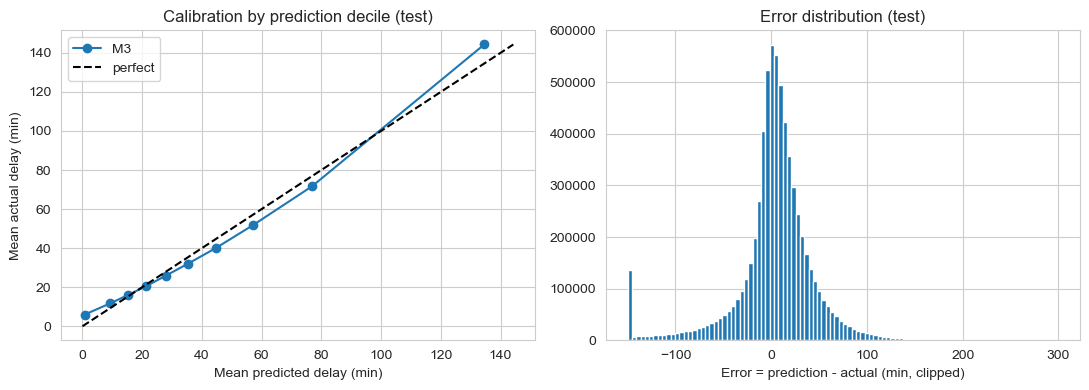

In [114]:
R_test["pred_decile"] = pd.qcut(R_test["pred"], 10, duplicates="drop")
cal = R_test.groupby("pred_decile", observed=True)[["pred", "delay"]].mean()
display(cal.round(2))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(cal["pred"], cal["delay"], "o-", label="M3")
lim = [0, max(cal.max())]
ax[0].plot(lim, lim, "k--", label="perfect")
ax[0].set_xlabel("Mean predicted delay (min)"); ax[0].set_ylabel("Mean actual delay (min)")
ax[0].set_title("Calibration by prediction decile (test)"); ax[0].legend()
ax[1].hist(R_test["err"].clip(-150, 300), bins=100)
ax[1].set_xlabel("Error = prediction - actual (min, clipped)"); ax[1].set_title("Error distribution (test)")
plt.tight_layout(); plt.show()

### PHASE 10: FINAL MODEL CHOICE AND FINAL EVALUATION
#### A. What are we doing?
Test window sizes of 3, 7, 14 and 30 days on validation only.
Choose the final configuration, then refit on all training and validation data (Feb–Nov 2025) and score test once.
Report the final table, including a "delay ≤ 300" version and a train-only bootstrap-free confidence note.
#### B. Why?

The window size was my choice, so it should be tuned on validation, not test. The final model should use all data before the test period, as a real forecaster would.

#### C. Concepts
Hyperparameter tuning on validation: choose settings using the validation split so test remains an honest final exam.
Refit on train + validation: more recent data, including November, before predicting December onwards.
Single final test: test is scored once after all choices are made.

In [121]:
# Global variables that history_feature() needs (Cell 8.1 deleted y)
y = base["cap"].to_numpy("float64")
days = pd.date_range(base["date"].min().normalize(), base["date"].max().normalize())
nD = len(days)
d_idx = (base["date"] - days[0]).dt.days.to_numpy().astype("int64")

def build_hist(k):
    tcode, tuni = pd.factorize(base["train_no"])
    scode, suni = pd.factorize(base["station_name"])
    return {
        "th7": history_feature(tcode, len(tuni), k),
        "sh7": history_feature(scode, len(suni), k),
        "g7":  history_feature(np.zeros(len(base), dtype="int64"), 1, k),
    }

rng = np.random.RandomState(42)
fit_rows_idx = rng.choice(np.flatnonzero(tr.to_numpy()), 3_000_000, replace=False)
mu, enc = make_encoders("delay")
USE = ["th7", "sh7", "g7"]
win_res = []
orig = {c: base[c].copy() for c in USE}

for k in [3, 7, 14, 30]:
    H = build_hist(k)
    for c in H:
        base[c] = H[c]
    fr = base.iloc[fit_rows_idx]
    m = LinearRegression().fit(build_X3(fr, enc, mu, USE), fr["delay"])
    vr = base.loc[va]
    p = m.predict(build_X3(vr, enc, mu, USE))
    win_res.append({"window_days": k, **metrics(vr["delay"], p)})
    print("done k =", k)

for c in orig:
    base[c] = orig[c]          # restore the 7-day versions
display(pd.DataFrame(win_res).round(3))

done k = 3
done k = 7
done k = 14
done k = 30


,window_days,MAE,RMSE,R2,bias
0,3,26.354,49.153,0.384,0.534
1,7,26.086,48.650,0.396,0.103
2,14,25.959,48.741,0.394,-0.494
3,30,25.922,49.165,0.383,-1.694


In [123]:
# ---- Final refit on train + validation (everything before the test period) ----
tv = base["date"] < "2025-12-01"
K = 20

def make_encoders_tv(target):
    d = base.loc[tv, ["train_no", "station_name", target]]
    mu = float(d[target].mean())
    enc = {}
    for col in ["train_no", "station_name"]:
        g = d.groupby(col, observed=True)[target].agg(["count", "mean"]).astype("float64")
        enc[col] = (g["count"] * g["mean"] + K * mu) / (g["count"] + K)
    return mu, enc

# Safety check: the 7-day columns were restored (earlier value for row 20,000,000 was 49.24643)
print("th7 at row 20,000,000:", base["th7"].iat[20_000_000], "(expect about 49.246)")

rng = np.random.RandomState(42)
idx = rng.choice(np.flatnonzero(tv.to_numpy()), 3_000_000, replace=False)
fr = base.iloc[idx]
te_rows = base.loc[te]
USE = ["th7", "sh7", "g7"]

mu_d, enc_d = make_encoders_tv("delay")
mu_c, enc_c = make_encoders_tv("cap")

m3  = LinearRegression().fit(build_X3(fr, enc_d, mu_d, USE), fr["delay"])
m3c = LinearRegression().fit(build_X3(fr, enc_c, mu_c, USE), fr["cap"])
m2  = LinearRegression().fit(build_X3(fr, enc_d, mu_d, []),  fr["delay"])

preds = {
    "Constant: train+val mean":      np.full(len(te_rows), float(base.loc[tv, "delay"].mean())),
    "M2 (no history)":               m2.predict(build_X3(te_rows, enc_d, mu_d, [])),
    "M3 final (raw target)":         m3.predict(build_X3(te_rows, enc_d, mu_d, USE)),
    "M3 capped target (sensitivity)": m3c.predict(build_X3(te_rows, enc_c, mu_c, USE)),
}

y_te = te_rows["delay"].to_numpy("float64")
small = y_te <= 300
rows = []
for name, p in preds.items():
    p = np.asarray(p, dtype="float64")
    rows.append({"model": name, "subset": "all test rows", "n": len(y_te), **metrics(y_te, p)})
    rows.append({"model": name, "subset": "actual delay <= 300", "n": int(small.sum()),
                 **metrics(y_te[small], p[small])})
final = pd.DataFrame(rows).round(3)
display(final)
print("M3 final coefficients:",
      dict(zip(build_X3(fr.head(5), enc_d, mu_d, USE).columns, m3.coef_.round(3))))

# ---- Stability check: resample test DAYS with replacement (1000 times) ----
p3 = np.asarray(preds["M3 final (raw target)"], dtype="float64")
dd = pd.DataFrame({"day": te_rows["date"].to_numpy(), "y": y_te,
                   "sse": (p3 - y_te) ** 2})
dd["y2"] = dd["y"] ** 2
g = dd.groupby("day").agg(n=("y", "size"), sy=("y", "sum"), sy2=("y2", "sum"), sse=("sse", "sum"))
bs_r2, bs_rmse = [], []
b = np.random.RandomState(0)
for _ in range(1000):
    s = g.iloc[b.randint(0, len(g), len(g))]
    n, sy, sy2, sse = s["n"].sum(), s["sy"].sum(), s["sy2"].sum(), s["sse"].sum()
    bs_r2.append(1 - sse / (sy2 - sy ** 2 / n))
    bs_rmse.append(np.sqrt(sse / n))
print("\nTest days:", len(g))
print("R2   95% range over resampled days:", np.round(np.percentile(bs_r2, [2.5, 97.5]), 3))
print("RMSE 95% range over resampled days:", np.round(np.percentile(bs_rmse, [2.5, 97.5]), 2))

final.to_csv(r"D:\Indian_Railway_Delay_Project\final_test_results.csv", index=False)

th7 at row 20,000,000: 49.24643 (expect about 49.246)


,model,subset,n,MAE,RMSE,R2,bias
0,Constant: train+val mean,all test rows,6672925,38.179,73.336,-0.012,-7.939
1,Constant: train+val mean,actual delay <= 300,6577662,32.549,48.250,-0.002,-1.872
2,M2 (no history),all test rows,6672925,30.548,62.627,0.262,-7.941
3,M2 (no history),actual delay <= 300,6577662,25.988,41.662,0.253,-3.088
4,M3 final (raw target),all test rows,6672925,30.282,58.267,0.361,0.134
5,M3 final (raw target),actual delay <= 300,6577662,26.307,40.093,0.309,4.536
6,M3 capped target (sensitivity),all test rows,6672925,29.677,59.373,0.337,-2.906
7,M3 capped target (sensitivity),actual delay <= 300,6577662,25.310,38.745,0.354,1.849


M3 final coefficients: {'station_no': 0.371, 'dist': 0.008, 'morning': 1.674, 'afternoon': 1.243, 'evening': 2.912, 'te_train': 0.528, 'te_station': -0.302, 'hist_train7': 0.473, 'hist_station7': 0.438, 'hist_system7': 0.171}

Test days: 69
R2   95% range over resampled days: [0.351 0.37 ]
RMSE 95% range over resampled days: [55.81 60.58]


## PHASE 11: REPORT AND PPT MATERIAL
A. What are we doing?

Turning the work into a report, a PPT and viva preparation, using only numbers that appeared in your outputs.

B. Master results to quote
Item	Value
Raw data	about 36.5M stop records, Feb 2025 to Feb 2026
After cleaning and jump removal	36,480,745 rows (4,084 journeys / 0.20% removed)
Modelling table	35,524,132 rows (956,613 without a schedule match dropped)
Split	Train Feb to Oct 2025 (25,879,636); validation Nov 2025 (2,971,571); test Dec 2025 to Feb 2026 (6,672,925)


Final features	station number, distance, 3 time-of-day dummies, train and station target encoding, 7-day history for the train, station and network
Final test	MAE 30.28, RMSE 58.27, R² 0.361, bias +0.13
Baseline test	MAE 38.18, RMSE 73.34, R² −0.012, bias −7.94
Story of improvement (test R²)	0.072 (M1) → 0.253 (M2) → 0.359 (M3)


B2. Report outline
Problem and objective
Data and cleaning (Phases 1 to 4)
EDA and correlation findings (Phases 3, 5)
Leakage decisions (previous-stop delay excluded, time split)
Features and encoding (Phases 6 to 8)
Models and results (Phases 7, 8, 10)
Error analysis (Phase 9)
Limitations and future work
Conclusion


B3. PPT plan (12 slides)
#	Slide	Key message
1	Title	Predicting train delay with Linear Regression
2	Problem and data	36M stop records, one year
3	Cleaning	Missing delays and 4,084 jump journeys removed, skewness 19.68 → 6.51
4	What drives delay	Train 29%, station 11%, distance 5% of variance; weekday 0%
5	Avoiding leakage	Previous-stop delay (r 0.965) excluded; split by time
6	Features	Encoding, 7-day history, VIF below 6
7	Model ladder	R² 0.07 → 0.25 → 0.36 (chart)
8	Final result	Table with the baseline
9	Bias fixed	−8.3 → +0.1 by month
10	Where it fails	1.43% of rows carry 53.3% of squared error
11	Limitations	One year, missing weather, 2.62% dropped, modest R²
12	Conclusion and future work	Add weather and disruption data, test gradient boosting


B4. Limitations to state honestly
The data covers one year, so the model has seen only one winter, and the seasonal shift was partly handled by history features, not learned.
2.62% of rows had no schedule match (late stops of routes where the schedule file is shorter), so the scope is "stops covered by the schedule".
The model cannot foresee rare extreme delays (above 300 minutes), which cause 53.3% of squared error.


Linear Regression is a simple model, and the weak fit is also a data limit (no weather, congestion or disruptions, hypothesis).
The train and station encoding in the fit sample includes each row's own delay. This can only weaken the fitted weights, and validation and test rows are clean.
The 7-day history assumes data from the previous days is available at prediction time.
B5. Optional extras (only if your teacher asks)
A clearly labelled "live" model using the previous stop's delay (R² around 0.9 by Phase 5, only usable after departure).

A non-linear comparison model (for example gradient boosting) on the same features

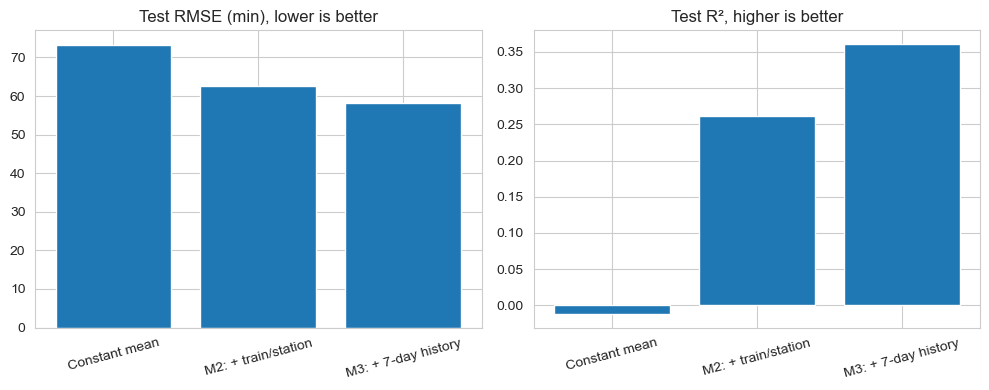

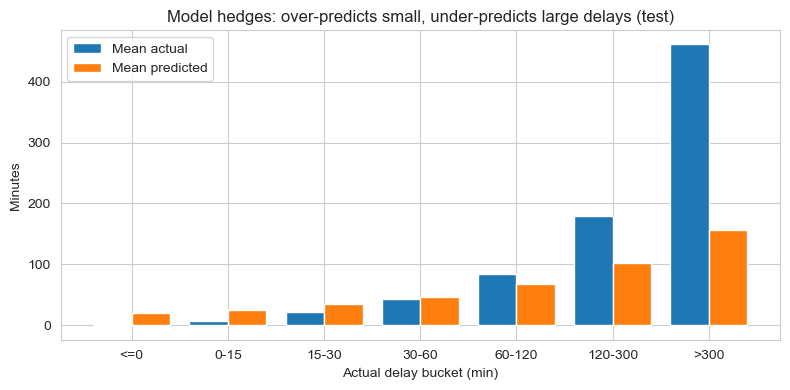

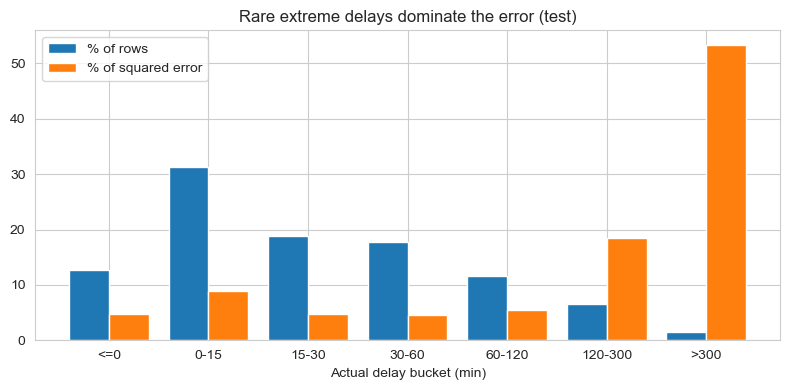

In [134]:
import os
import matplotlib.pyplot as plt

OUT = r"D:\Indian_Railway_Delay_Project\figures"
os.makedirs(OUT, exist_ok=True)

# Fig 1: model comparison on all test rows (from Cell 10.2 table `final`)
a = final[final["subset"] == "all test rows"].set_index("model")
names = ["Constant: train+val mean", "M2 (no history)", "M3 final (raw target)"]
labels = ["Constant mean", "M2: + train/station", "M3: + 7-day history"]
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].bar(labels, a.loc[names, "RMSE"]); ax[0].set_title("Test RMSE (min), lower is better")
ax[1].bar(labels, a.loc[names, "R2"]);   ax[1].set_title("Test R², higher is better")
for x in ax: x.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.savefig(OUT + r"\fig1_model_comparison.png", dpi=200); plt.show()

# Fig 2: mean actual vs mean predicted by size of actual delay (Phase 9 output)
bk = ["<=0", "0-15", "15-30", "30-60", "60-120", "120-300", ">300"]
act = [-1.49, 7.38, 22.35, 43.10, 84.24, 178.83, 460.95]
prd = [20.13, 25.70, 34.87, 46.95, 67.31, 101.67, 156.83]
fig, ax = plt.subplots(figsize=(8, 4))
w = 0.4; xs = np.arange(len(bk))
ax.bar(xs - w/2, act, w, label="Mean actual"); ax.bar(xs + w/2, prd, w, label="Mean predicted")
ax.set_xticks(xs); ax.set_xticklabels(bk); ax.set_xlabel("Actual delay bucket (min)")
ax.set_ylabel("Minutes"); ax.set_title("Model hedges: over-predicts small, under-predicts large delays (test)")
ax.legend(); plt.tight_layout(); plt.savefig(OUT + r"\fig2_actual_vs_pred.png", dpi=200); plt.show()

# Fig 3: share of rows vs share of squared error by actual delay bucket
rows_pct = [12.73, 31.20, 18.79, 17.72, 11.56, 6.57, 1.43]
sq_pct   = [4.67, 8.84, 4.73, 4.59, 5.48, 18.42, 53.28]
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(xs - w/2, rows_pct, w, label="% of rows"); ax.bar(xs + w/2, sq_pct, w, label="% of squared error")
ax.set_xticks(xs); ax.set_xticklabels(bk); ax.set_xlabel("Actual delay bucket (min)")
ax.set_title("Rare extreme delays dominate the error (test)"); ax.legend()
plt.tight_layout(); plt.savefig(OUT + r"\fig3_error_share.png", dpi=200); plt.show()

## PHASE 12: FINAL CONCLUSIONS
- Final model: Linear Regression with 10 features, raw delay target, 7-day history, trained on Feb to Nov 2025.
- Test result (Dec 2025 to Feb 2026, 6,672,925 rows): MAE 30.28, RMSE 58.27, R² 0.361, bias +0.13 minutes.
- Baseline (always predict the mean): MAE 38.18, RMSE 73.34, R² -0.012.
- Resampling the 69 test days gave an R² range of 0.351 to 0.370.
- Main limitation: delays above 300 minutes are 1.43% of rows but 53.3% of squared error and are under-predicted.
- The data has no weather, congestion or disruption information, and covers one year only.
- Future work: add weather and disruption data, and test a non-linear model such as gradient boosting.